# AI as a Substitute for Classroom Teachers in Higher Education — analysis notebook

Hierarchical fuzzy inference system (Teacher Replacement Feasibility Score, TRFS), activity classification,
ANN vs. benchmark models, factor importance and robustness, on the open **Global ChatGPT Student Survey**
(Ravšelj et al., Mendeley Data, doi:10.17632/ymg9nsn6kn.2, CC BY 4.0).

The notebook calls the same functions as `src/run_pipeline.py`, so every number matches the manuscript.
The two slow steps (30-fold cross-validation and 500 Monte Carlo fuzzy designs, ~30 min) are switched off by
default and their saved results are loaded instead; set `RUN_CV` / `RUN_ROBUSTNESS` to `True` to recompute them.

## 0. Setup (Google Colab or local)

In [1]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and not os.path.exists("Data-Visualization"):
    !git clone -q https://github.com/isratjahan829/Data-Visualization.git
    %cd Data-Visualization
    !git checkout -q claude/practical-darwin-bcbsl5
    %pip install -q -r ai-teacher-feasibility/requirements.txt
# locate the project folder
for cand in ["ai-teacher-feasibility", "..", "Data-Visualization/ai-teacher-feasibility"]:
    if os.path.exists(os.path.join(cand, "src", "run_pipeline.py")):
        PROJECT = os.path.abspath(cand); break
sys.path.insert(0, os.path.join(PROJECT, "src"))
os.chdir(os.path.join(PROJECT, "src"))
print("project:", PROJECT)

RUN_CV = False          # True -> re-run 10x3 repeated CV of all models (~20 min)
RUN_ROBUSTNESS = False  # True -> re-run 500 Monte Carlo fuzzy designs (~15 min)

project: /home/user/Data-Visualization/ai-teacher-feasibility


In [2]:
import json, warnings
import numpy as np, pandas as pd
from IPython.display import Image, display
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

import run_pipeline as rp
import figures
from config import *
from data_prep import load_raw, build_sample, save_processed
TABLES.mkdir(parents=True, exist_ok=True); FIGURES.mkdir(parents=True, exist_ok=True)

## 1. Data and analytic sample

In [3]:
raw = load_raw()
d, scored, flow = build_sample(raw)
print(raw.shape); print(flow)
demo = rp.describe_sample(raw, d, flow)
demo.round(1)

(23218, 174)
{'total_responses': 23218, 'chatgpt_users': 16010, 'valid_age_18_100': 15888, 'complete_on_model_items': 12206, 'after_straightlining_removal': 11920}


,variable,category,n,pct
0,Q2,Female,6476,54.3
1,Q2,Male,5266,44.2
2,Q2,Prefer not to say,106,0.9
3,Q2,Other,50,0.4
4,Q8,Undergraduate,9856,82.7
5,Q8,Postgraduate (Master),1455,12.2
6,Q8,Doctoral,516,4.3
7,Q10,Social Sciences,4824,40.5
8,Q10,Applied Sciences,4274,35.9
9,Q10,Arts & Humanities,1423,11.9


## 2. Measurement model (reliability, CFA, HTMT)

In [4]:
ct, phi, H = rp.measurement(raw, scored)
print(rp.SUMMARY["cfa_fit"])
display(ct.round(3))
display(H.round(2))
display(pd.read_csv(TABLES / "measurement_alternatives.csv").round(3))

{'n': 11920.0, 'chi2': 9046.683553389981, 'df': 271.0, 'CFI': 0.9397730785780898, 'TLI': 0.9277721422061962, 'RMSEA': 0.05212378225658747, 'SRMR': 0.045967068912424636, 'converged': True}


,loading_min,loading_max,CR,AVE,sqrtAVE,alpha,mean,sd,n_items,name
factor,,,,,,,,,,
TE,0.647,0.742,0.750,0.501,0.708,0.741,3.775,0.683,3,Teaching effectiveness
SE,0.676,0.747,0.746,0.495,0.704,0.742,3.597,0.790,3,Student engagement
P,0.707,0.786,0.779,0.541,0.736,0.772,3.553,0.785,3,Personalization
AC,0.743,0.795,0.819,0.602,0.776,0.817,3.426,0.862,3,Assessment capability
C,0.554,0.769,0.734,0.484,0.695,0.714,3.549,0.724,3,Communication
A,0.719,0.882,0.864,0.682,0.826,0.858,3.452,0.850,3,Adaptability
R,0.610,0.867,0.827,0.619,0.787,0.813,3.259,0.807,3,Reliability
E,0.538,0.882,0.870,0.579,0.761,0.867,3.010,0.951,5,Ethical suitability


,TE,SE,P,AC,C,A,R,E
TE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SE,0.51,NaN,NaN,NaN,NaN,NaN,NaN,NaN
P,0.55,0.76,NaN,NaN,NaN,NaN,NaN,NaN
AC,0.51,0.72,0.81,NaN,NaN,NaN,NaN,NaN
C,0.65,0.49,0.45,0.40,NaN,NaN,NaN,NaN
A,0.60,0.53,0.55,0.56,0.47,NaN,NaN,NaN
R,0.67,0.51,0.64,0.57,0.43,0.49,NaN,NaN
E,0.13,0.20,0.20,0.21,0.09,0.16,0.2,NaN


,mapping,n,CFI,TLI,RMSEA,SRMR,min_alpha,min_AVE,max_HTMT
0,M0 (initial a-priori mapping),12066,0.883,0.865,0.070,0.060,0.595,0.324,1.004
1,M1,12558,0.928,0.915,0.056,0.048,0.718,0.440,0.959
2,M2,12568,0.941,0.929,0.052,0.045,0.717,0.486,0.863
3,M3 (final),12564,0.940,0.928,0.052,0.045,0.718,0.487,0.806


## 3. Hierarchical fuzzy inference system → overall TRFS

In [5]:
d = rp.fuzzy_scores(d)
print({k: round(v, 2) if isinstance(v, float) else v for k, v in rp.SUMMARY["trfs"].items()})
pd.read_csv(TABLES / "table_trfs_validity.csv").round(3)

{'mean': 50.46, 'sd': 19.75, 'median': 50.0, 'class_pct': {'Partial AI assistance': 46.08221476510067, 'Full AI replacement': 28.104026845637588, 'Human involvement required': 25.813758389261743}, 'kw_usage_H': 1116.68, 'kw_usage_p': 0.0, 'rho_usage': 0.3}


,criterion,n,spearman_rho,p
0,TSI (ChatGPT easier/clearer than professors),11920,0.388,0.000
1,Q24e satisfied with assistance,11910,0.552,0.000
2,Q16 overall experience,11903,0.449,0.000
3,Q15 intensity of use,11898,0.301,0.000
4,Q22h ChatGPT might replace formal education,11912,-0.013,0.155


In [6]:
pd.read_csv(TABLES / "rules_TRFS.csv")

,Rule,PC,IQ,TW,TRFS
0,1,Low,Low,Low,Low
1,2,Low,Low,Medium,Low
2,3,Low,Low,High,Low
3,4,Low,Medium,Low,Low
4,5,Low,Medium,Medium,Low
5,6,Low,Medium,High,Medium
6,7,Low,High,Low,Low
7,8,Low,High,Medium,Medium
8,9,Low,High,High,Medium
9,10,Medium,Low,Low,Low


## 4. Activity-level feasibility and classification (RQ1, RQ4)

In [7]:
act, M = rp.activity_scores(d, scored)
print(rp.SUMMARY["activity_friedman"])
act.drop(columns=["items"]).round(2)

{'chi2': 5164.462882499801, 'p': 0.0, 'kendall_W': 0.04814003432606078, 'n': 11920, 'k': 10}


,code,activity,capability_mean,capability_sd,alpha,TRFS_mean,TRFS_sd,TRFS_median,ci_low,ci_high,pct_full,pct_partial,pct_human,category,tier,net_endorsement,rank
0,A1,Content explanation,3.80,0.66,0.67,54.67,18.45,55.36,54.34,55.01,31.64,52.04,16.32,Partial AI assistance,AI-leaning,15.33,1
1,A2,Question answering,3.65,0.68,0.69,53.27,18.25,50.00,52.94,53.62,28.67,53.47,17.86,Partial AI assistance,AI-leaning,10.81,2
2,A5,Personalized learning,3.46,0.88,0.72,50.94,19.30,50.00,50.58,51.30,22.22,57.34,20.44,Partial AI assistance,AI-leaning,1.79,3
3,A3,Assignment feedback,3.42,0.86,0.82,50.28,19.00,50.00,49.93,50.62,24.05,52.04,23.91,Partial AI assistance,Balanced,0.14,4
4,A4,Student assessment,3.36,0.93,0.80,49.36,19.60,50.00,49.00,49.72,20.32,56.09,23.59,Partial AI assistance,Human-leaning,-3.27,5
5,A6,Student motivation,3.32,0.94,0.75,49.08,19.81,50.00,48.73,49.44,20.08,55.91,24.02,Partial AI assistance,Human-leaning,-3.94,6
6,A8,Academic guidance,3.27,0.89,0.83,48.60,19.08,50.00,48.25,48.94,21.73,51.60,26.67,Partial AI assistance,Human-leaning,-4.94,7
7,A10,Emotional & social support,3.18,0.69,0.49,48.12,18.00,50.00,47.80,48.45,16.45,60.48,23.07,Partial AI assistance,Human-leaning,-6.62,8
8,A7,Classroom communication,3.23,0.85,0.53,48.11,19.02,50.00,47.77,48.46,16.06,60.39,23.55,Partial AI assistance,Human-leaning,-7.49,9
9,A9,Problem solving,3.14,0.94,0.86,46.52,19.42,50.00,46.17,46.89,18.98,49.92,31.11,Partial AI assistance,Human-leaning,-12.13,10


## 5. ANN vs. benchmark models (RQ3)

In [8]:
if RUN_CV:
    cv, summ = rp.predictive(d)
else:
    cv = pd.read_csv(TABLES / "cv_fold_scores.csv")
    summ = pd.read_csv(TABLES / "table_model_comparison.csv", index_col=0)
summ.round(3)

,MSE_mean,MSE_std,RMSE_mean,RMSE_std,MAE_mean,MAE_std,R2_mean,R2_std,seconds_mean,seconds_std,t_vs_ANN,p_vs_ANN
model,,,,,,,,,,,,
ANN (MLP),467.273,15.185,21.614,0.352,17.387,0.371,0.259,0.023,11.379,1.053,NaN,NaN
Gradient boosting,467.344,15.649,21.615,0.363,17.317,0.364,0.259,0.022,0.209,0.049,-0.032,0.975
Hybrid fuzzy-ANN,469.753,14.706,21.671,0.340,17.451,0.362,0.255,0.022,11.626,1.104,-2.636,0.013
Random forest,469.787,15.935,21.672,0.368,17.329,0.375,0.255,0.023,1.282,0.053,-1.300,0.204
Linear regression,471.752,15.884,21.717,0.368,17.534,0.380,0.252,0.023,0.010,0.007,-3.219,0.003
SVR (RBF),477.962,15.990,21.859,0.365,17.327,0.349,0.242,0.027,5.089,0.591,-5.484,0.000
Fuzzy HFIS (calibrated),533.565,19.204,23.095,0.417,18.697,0.392,0.155,0.021,0.003,0.002,-16.376,0.000


## 6. Factor importance (RQ2)

In [9]:
imp = rp.importance(d)
imp.round(3)

,factor,name,ann_perm_importance_R2_drop,ann_perm_importance_sd,fis_sensitivity_plus1SD,spearman_with_TSI,rank_ann,rank_fis
0,TE,Teaching effectiveness,0.020,0.003,0.580,0.195,5,8
1,SE,Student engagement,0.045,0.005,0.675,0.350,3,7
2,P,Personalization,0.045,0.008,1.042,0.388,4,5
3,AC,Assessment capability,0.075,0.006,1.310,0.402,2,3
4,C,Communication,0.003,0.002,0.981,0.165,8,6
5,A,Adaptability,0.016,0.004,1.201,0.276,6,4
6,R,Reliability,0.094,0.004,6.456,0.357,1,1
7,E,Ethical suitability,0.008,0.002,3.485,0.094,7,2


## 7. Robustness of the fuzzy design and subgroups

In [10]:
if RUN_ROBUSTNESS:
    rob, band = rp.robustness(d, act, draws=500)
else:
    rob = pd.read_csv(TABLES / "robustness_draws.csv")
    band = pd.read_csv(TABLES / "robustness_activity_bands.csv", index_col=0)
print("mean Kendall tau:", rob.kendall_tau.mean().round(3),
      "| mean category agreement:", rob.category_agreement.mean().round(3))
sg, hm = rp.subgroups(d)
hm.round(1)

mean Kendall tau: 0.953 | mean category agreement: 0.995


,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10
Q10,,,,,,,,,,
Applied Sciences,55.3,54.2,51.1,50.4,52.2,50.1,48.8,49.9,47.5,49.5
Arts & Humanities,53.4,51.5,49.4,48.5,50.1,49.0,48.3,47.9,46.4,47.7
Natural & Life Sciences,54.5,52.8,50.5,48.9,50.4,48.8,48.2,48.0,46.5,48.6
Social Sciences,54.4,53.1,49.7,48.7,50.1,48.1,47.3,47.7,45.6,46.9


## 8. Figures

fig10_activity_by_field.png


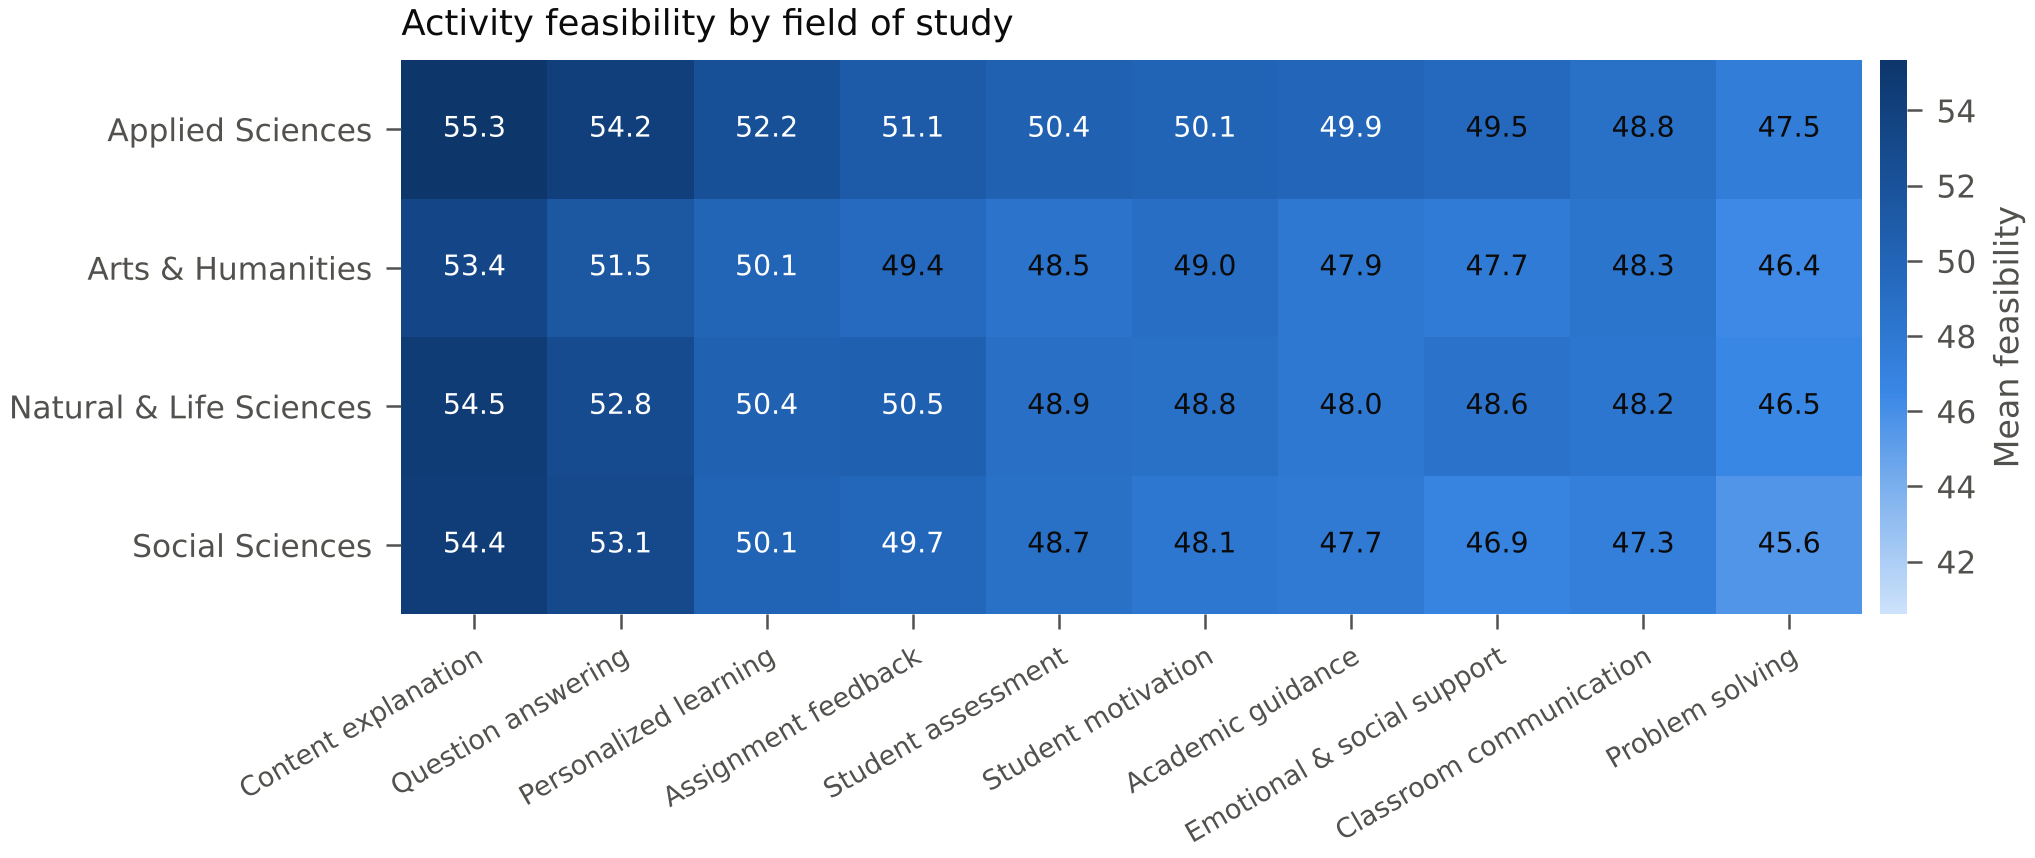

fig11_activity_raincloud.png


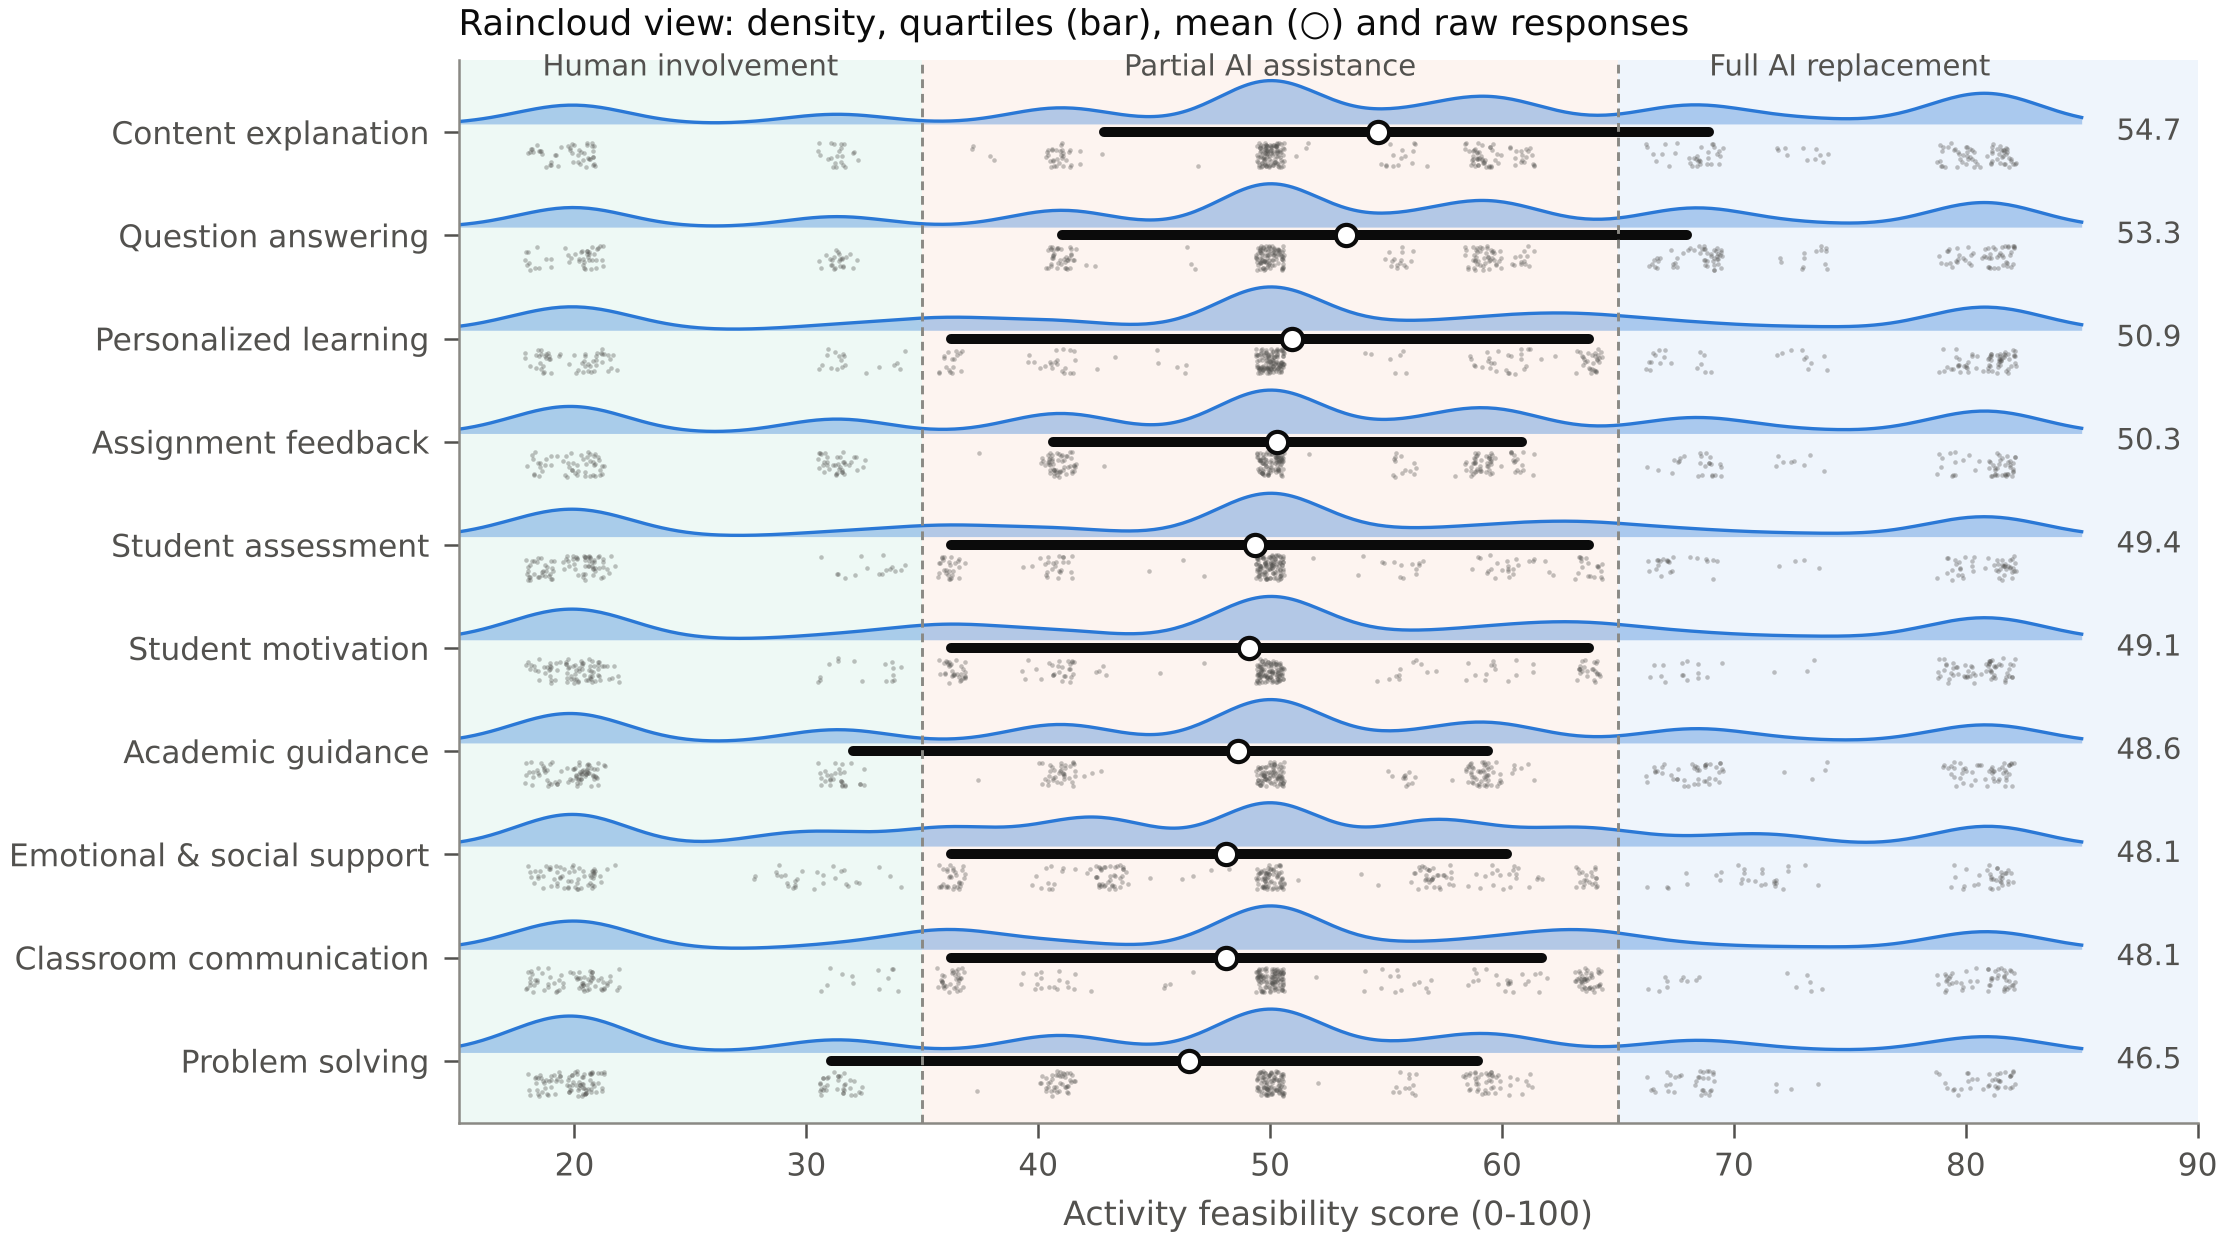

fig12_shapley_r2.png


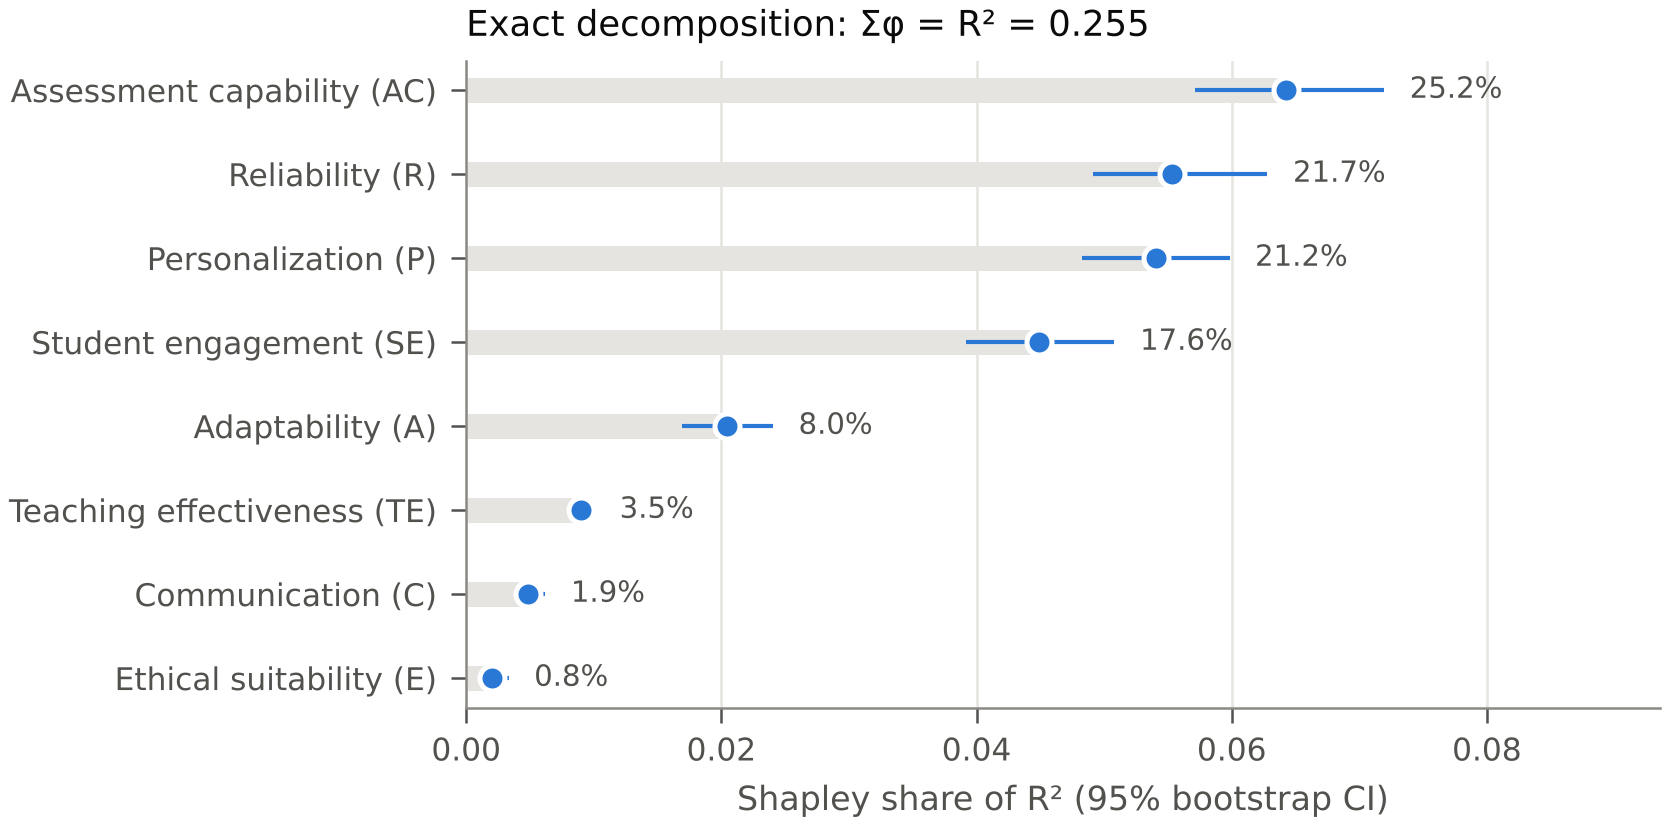

fig13_multilevel.png


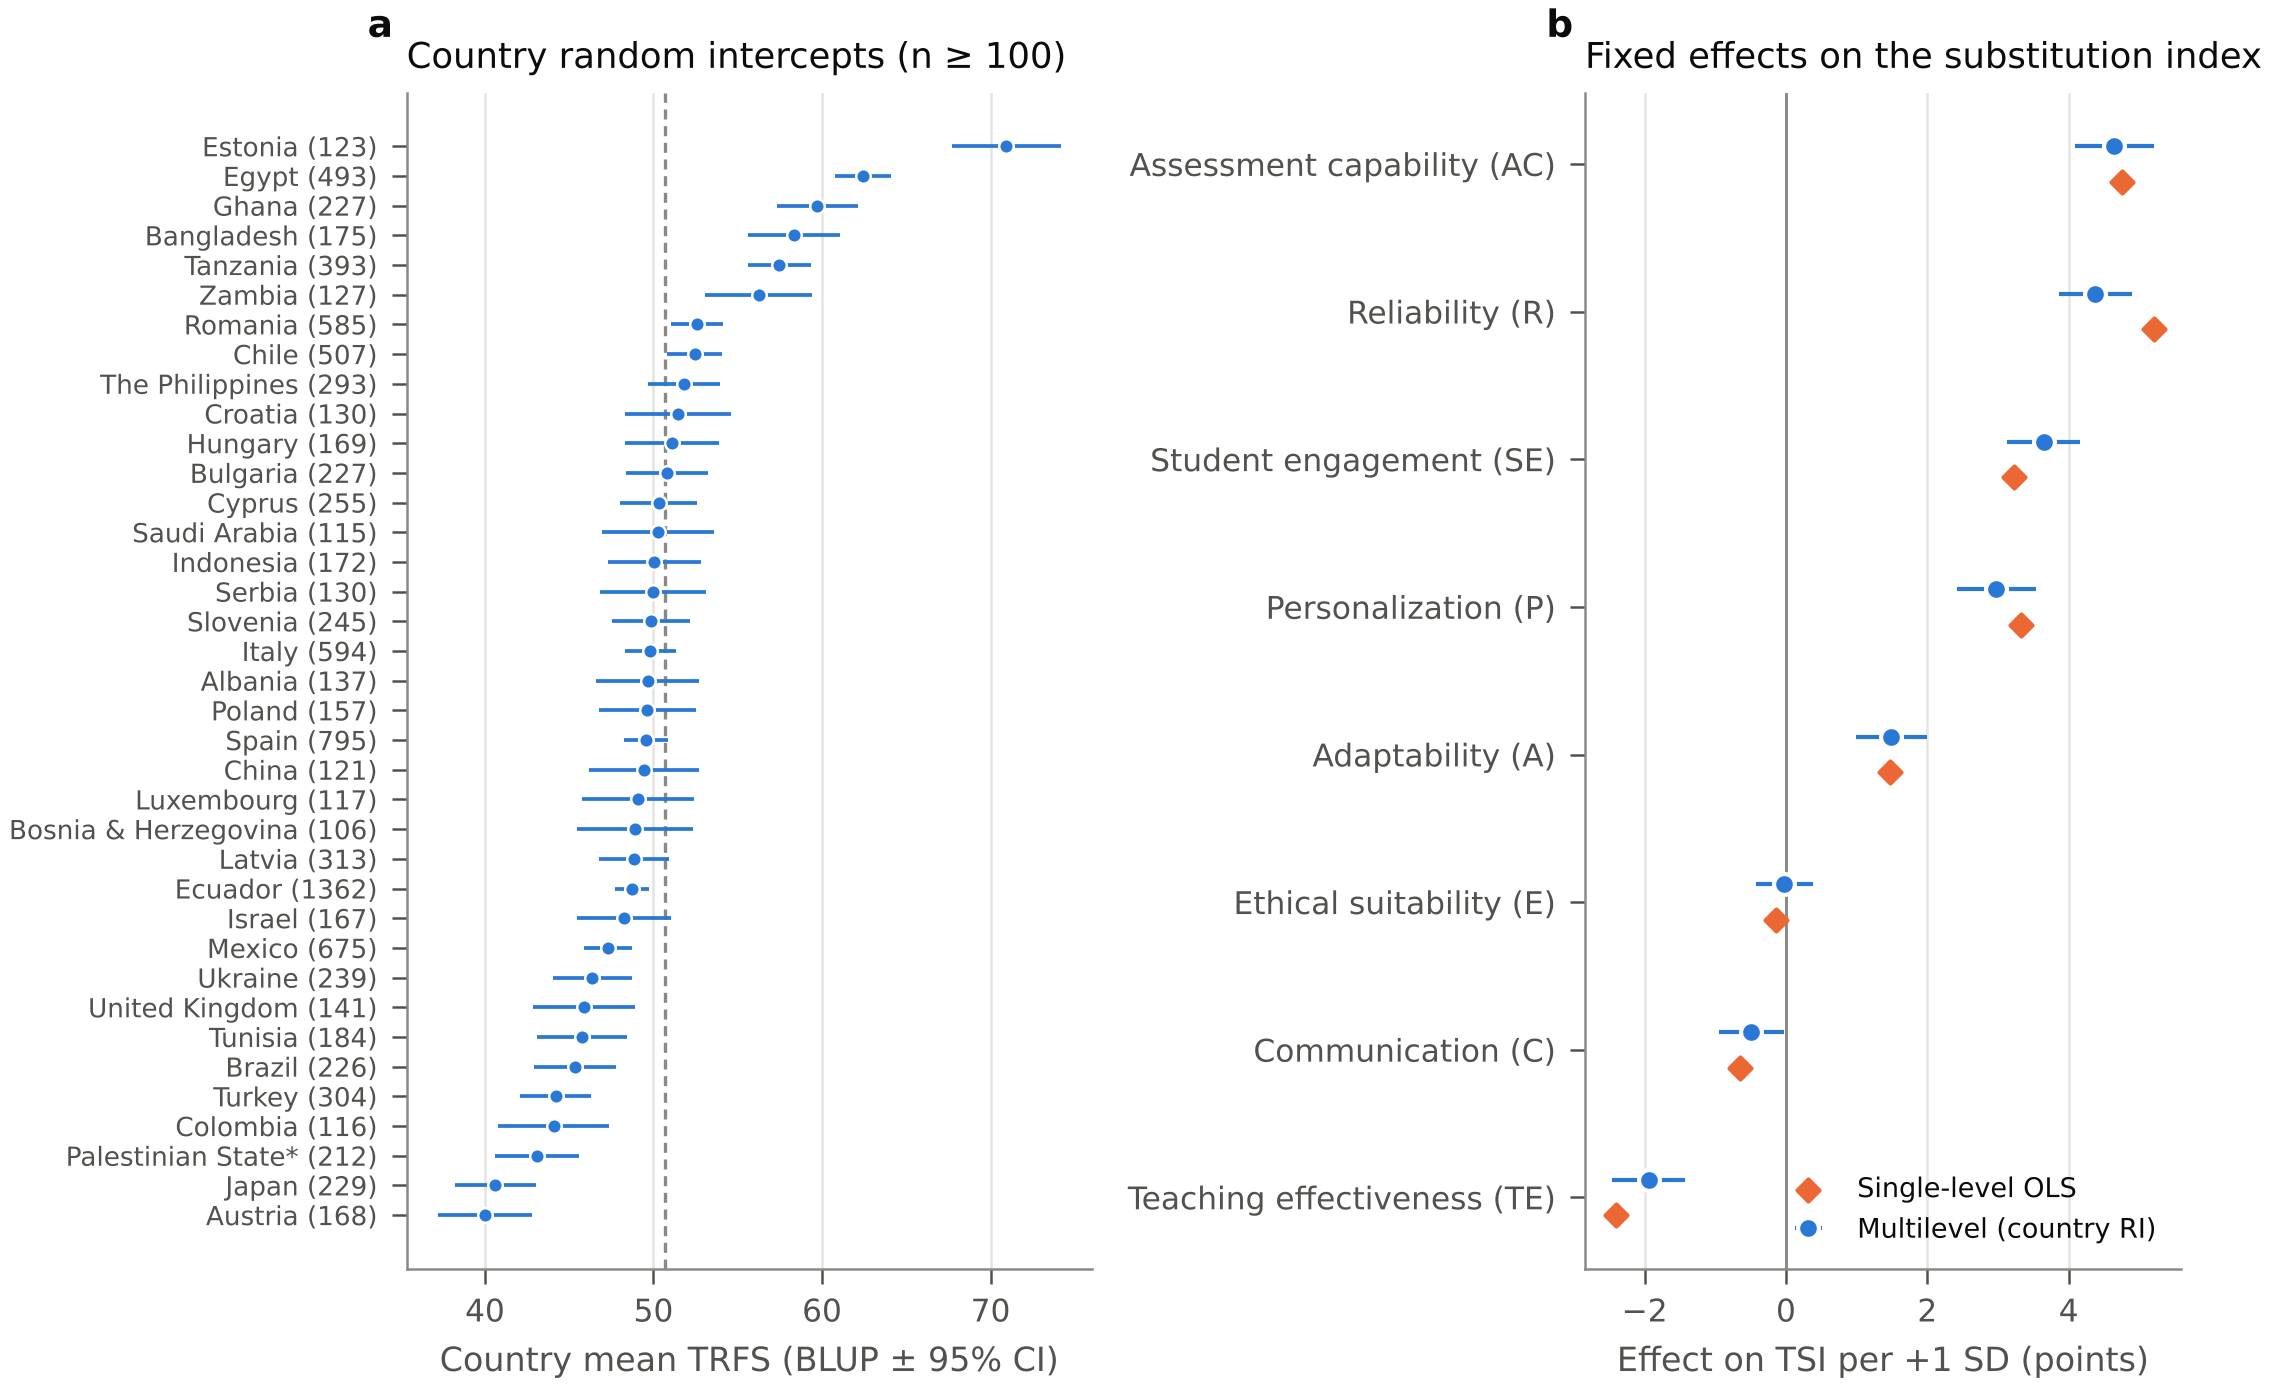

fig14_quantile_regression.png


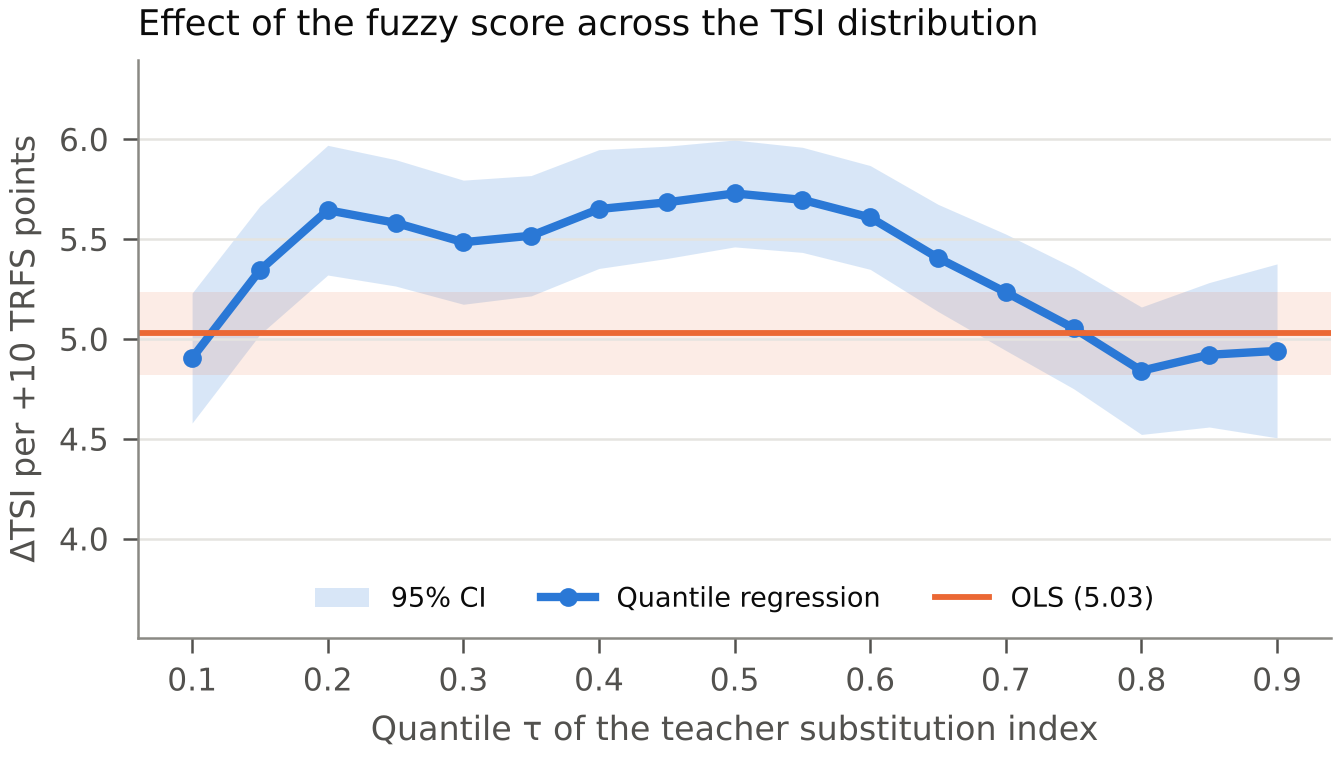

fig15_typology.png


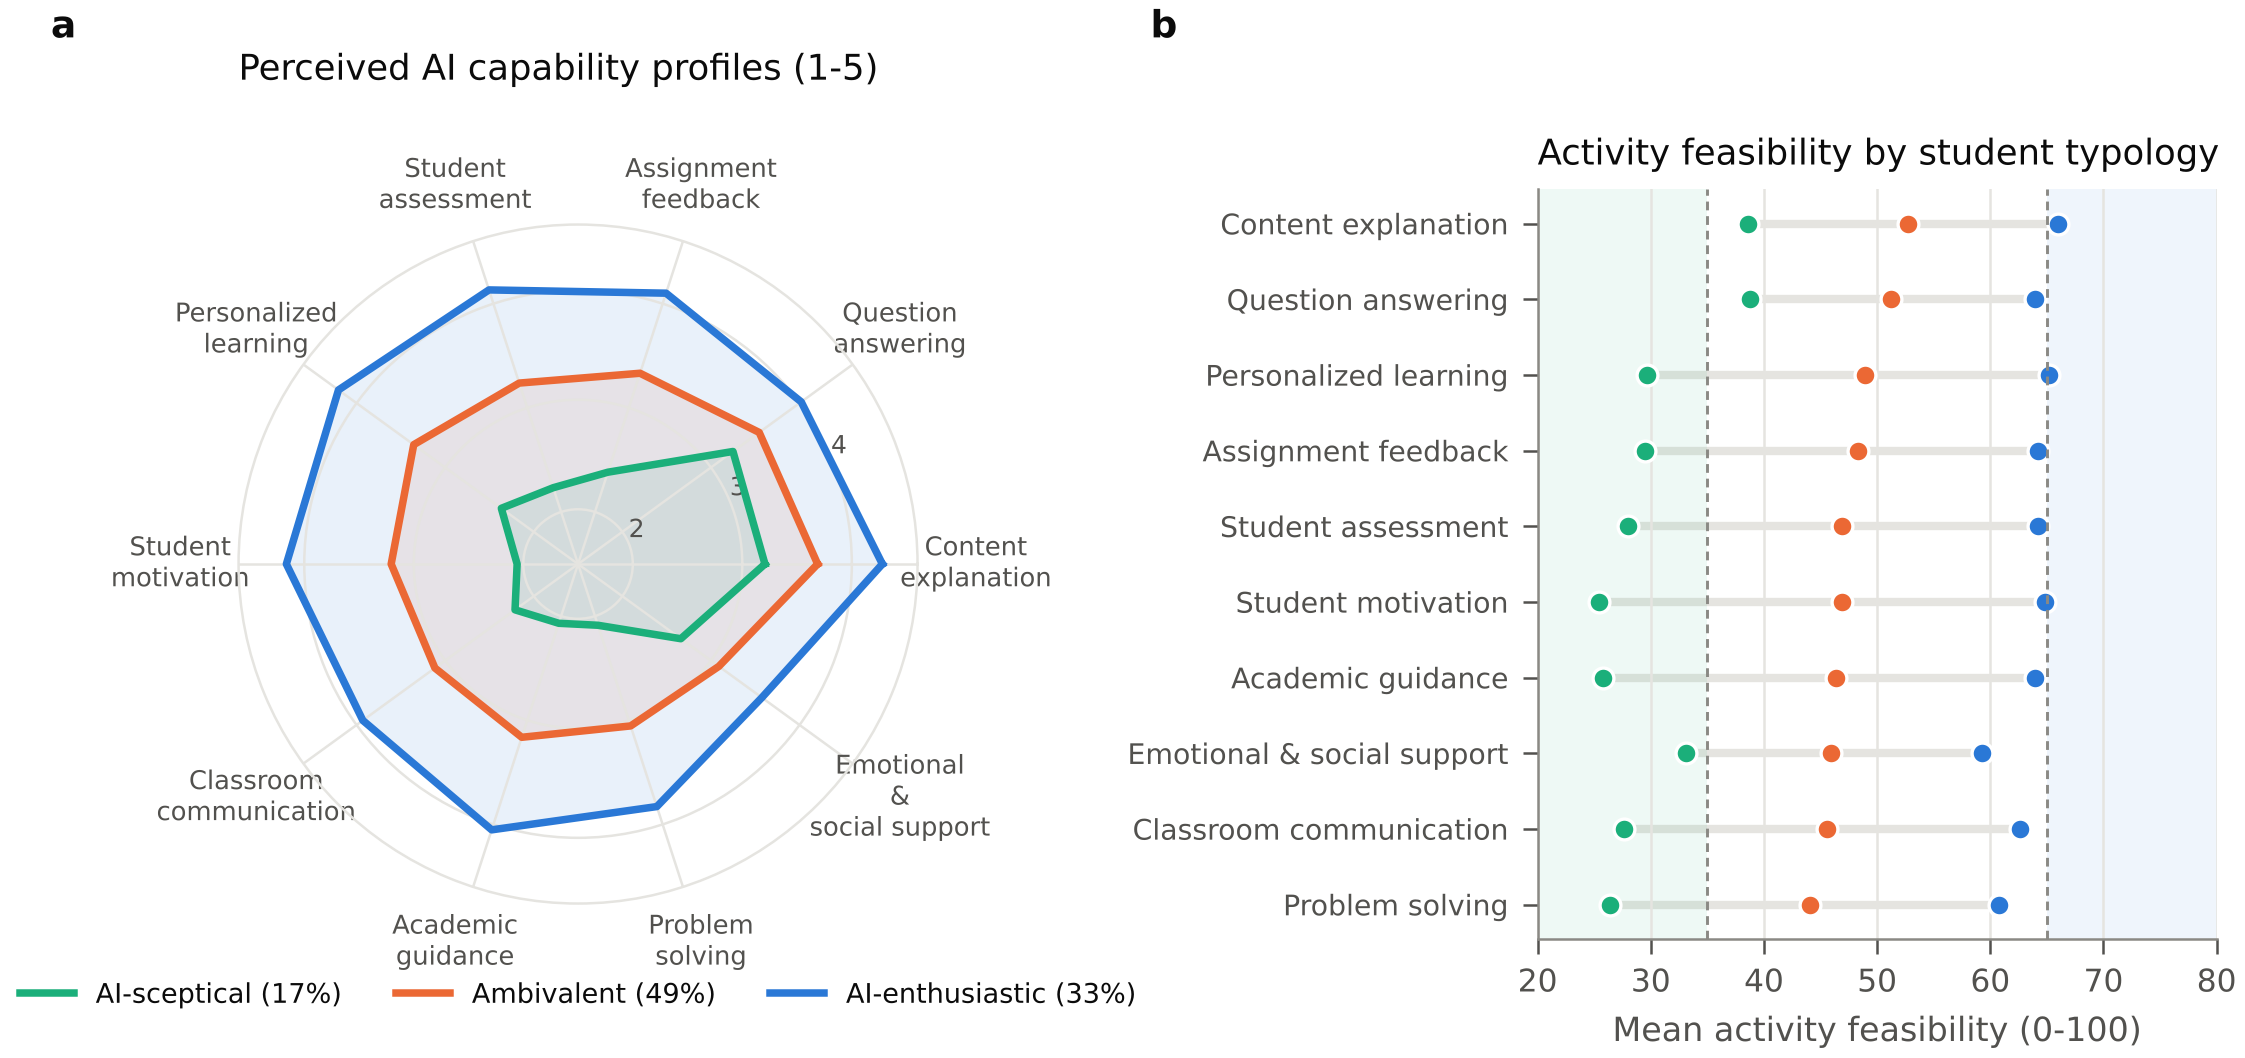

fig16_surfaces_3d.png


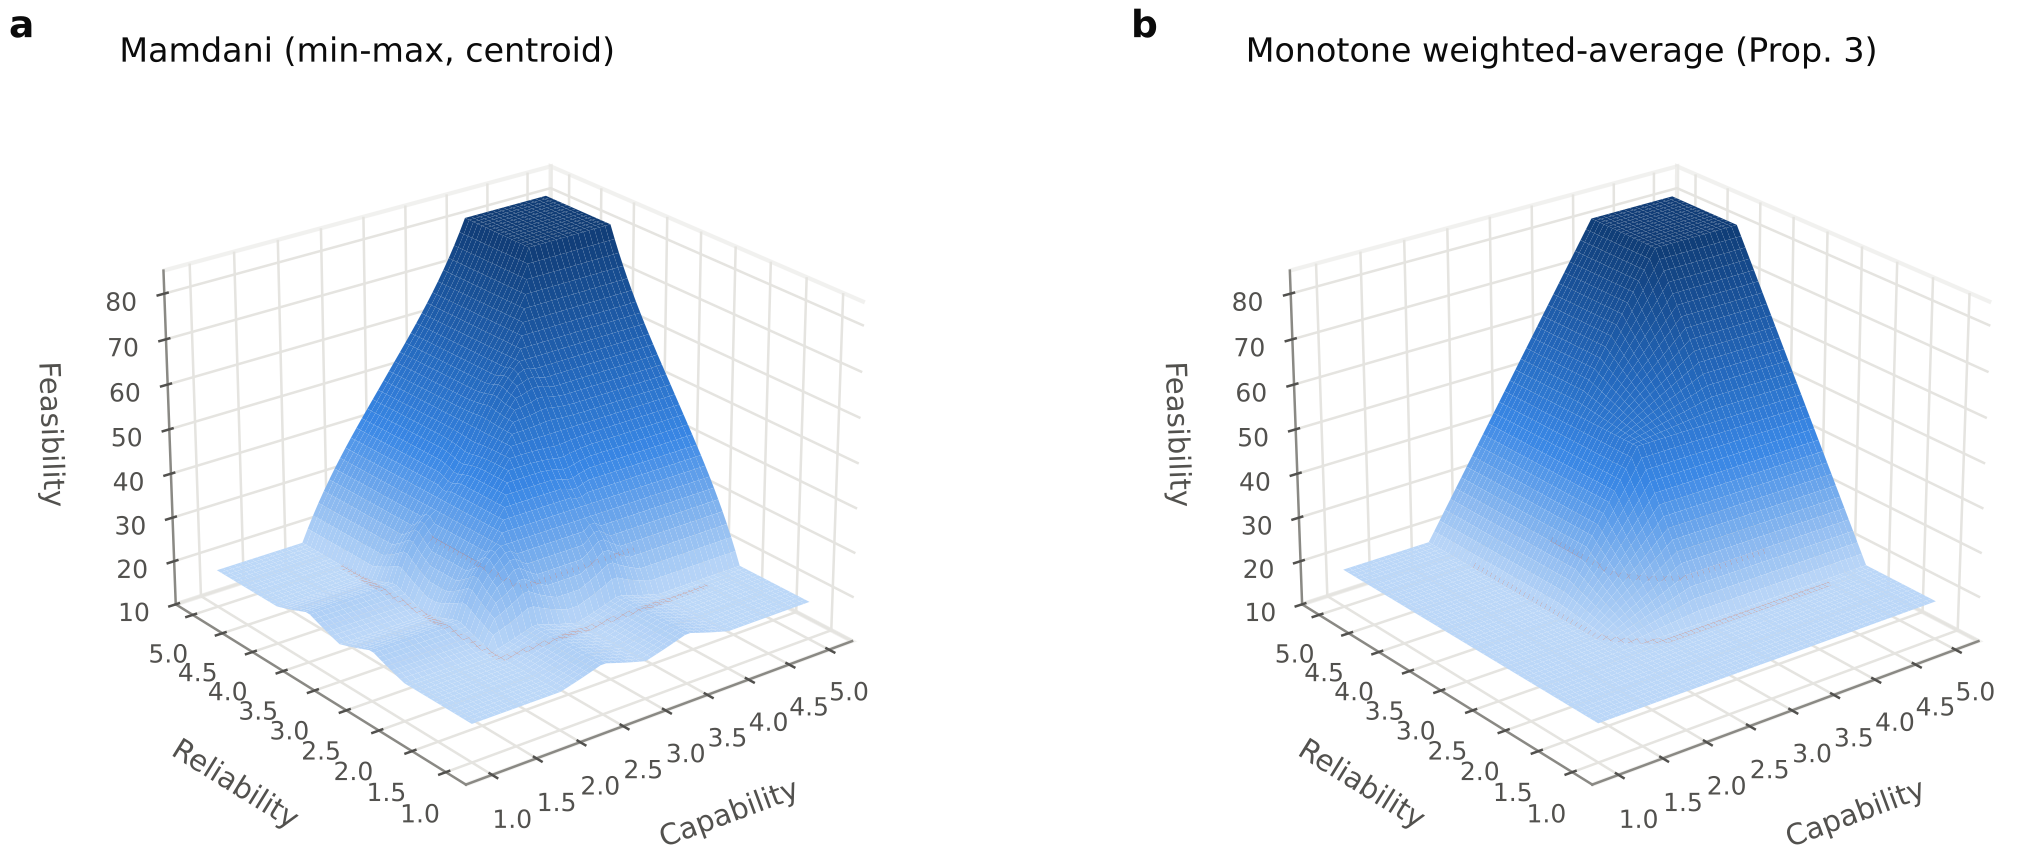

fig17_effects_and_variants.png


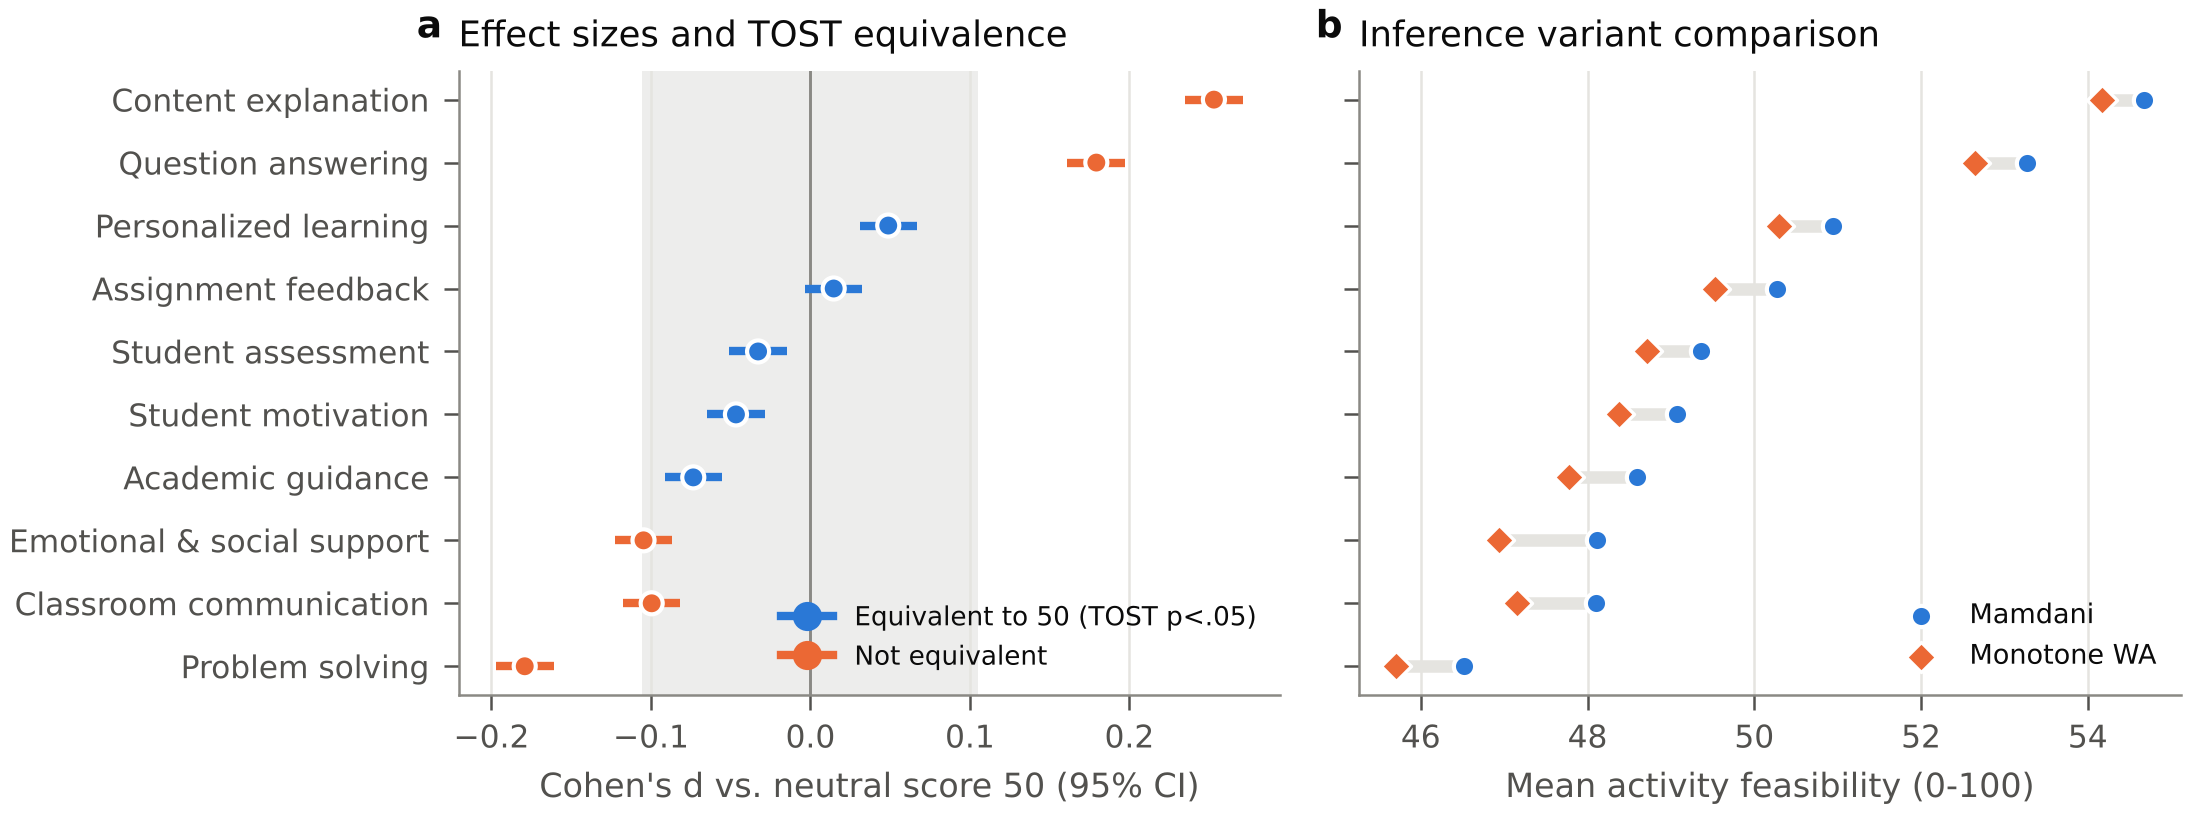

fig2_membership_functions.png


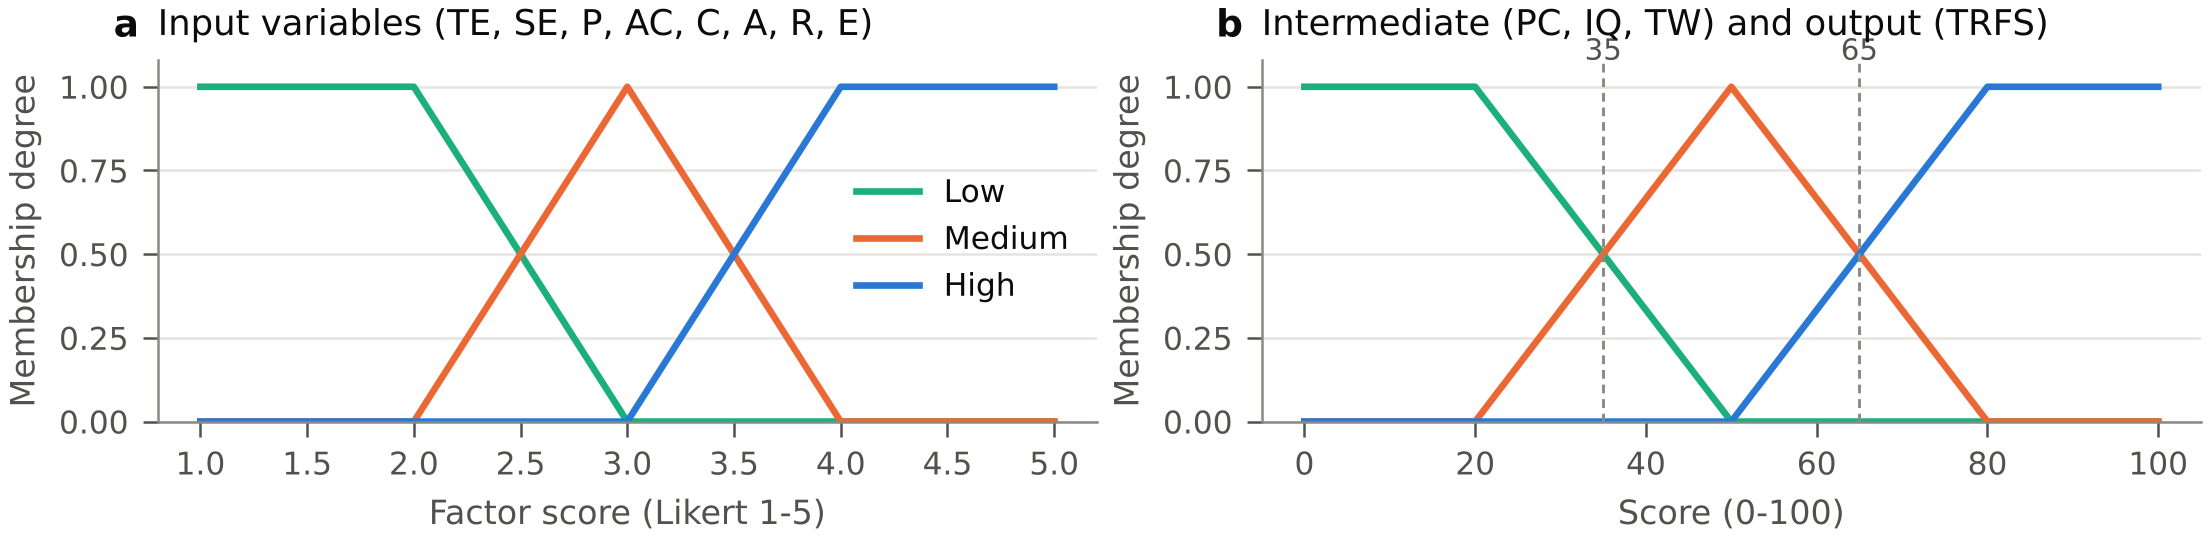

fig3_control_surfaces.png


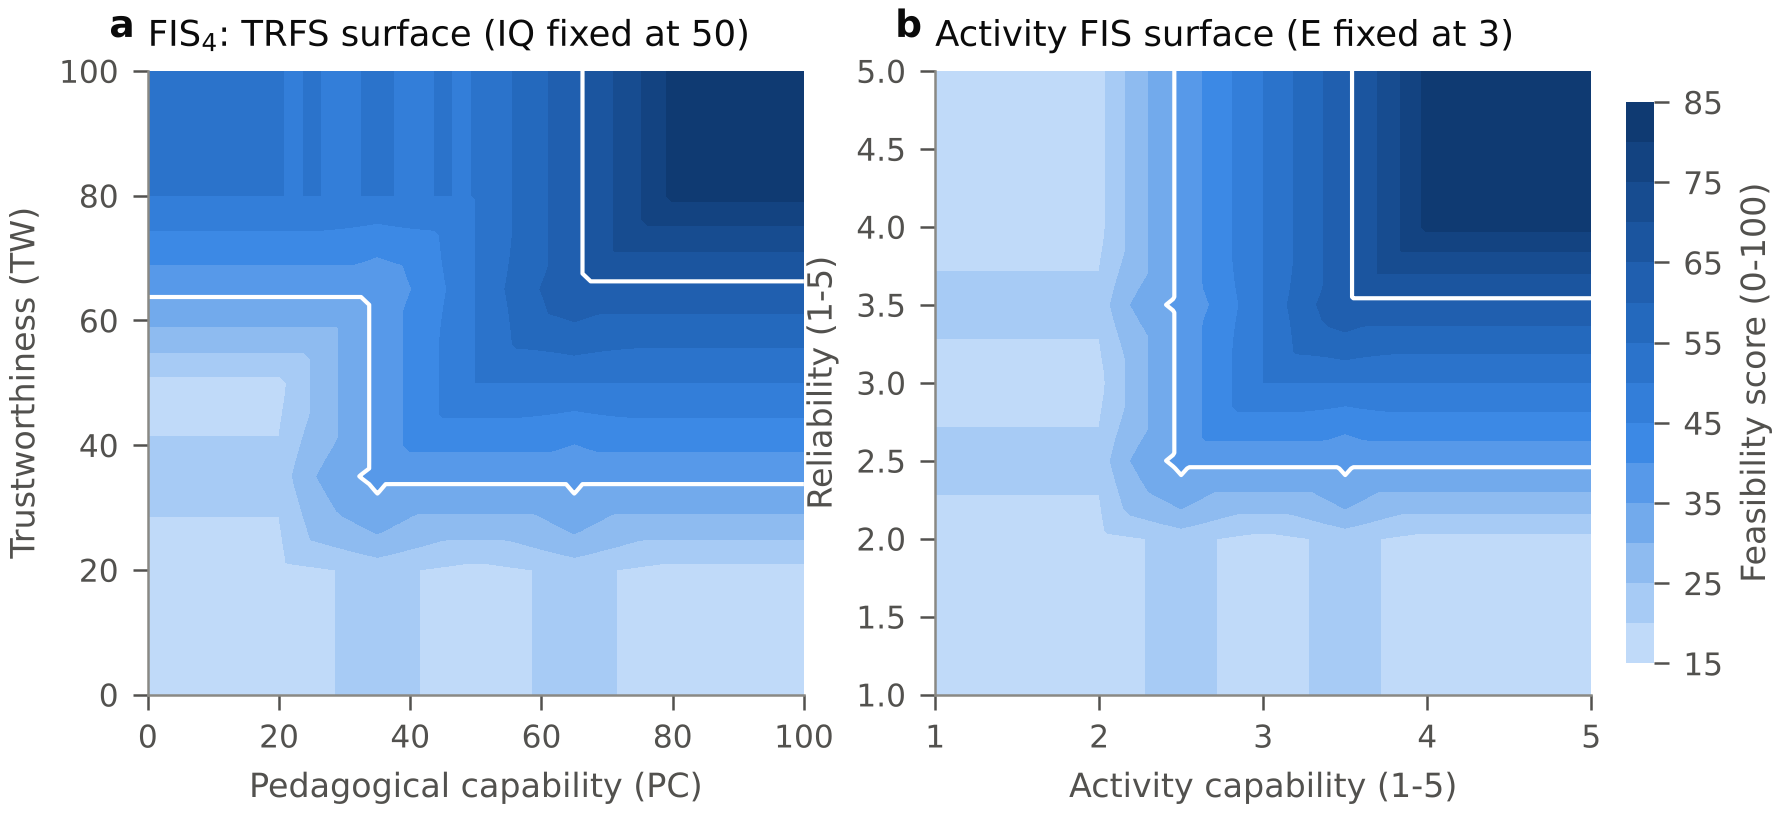

fig4_factor_profile.png


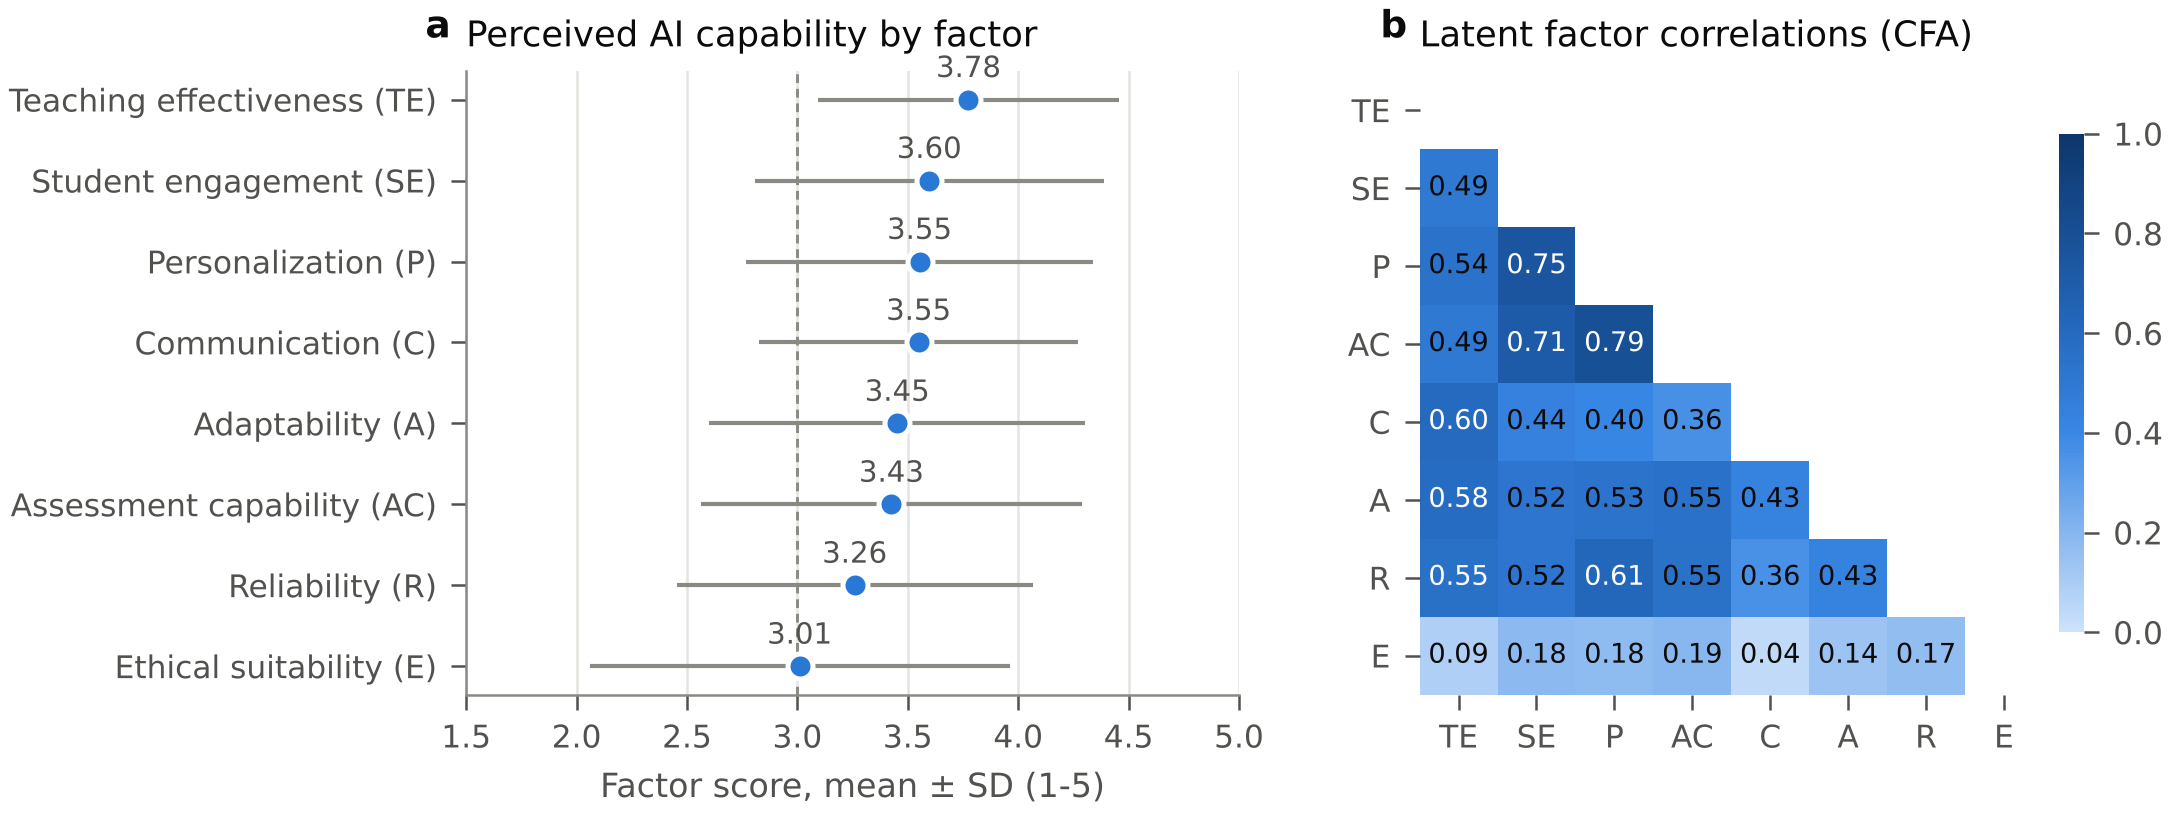

fig5_trfs_distribution_validity.png


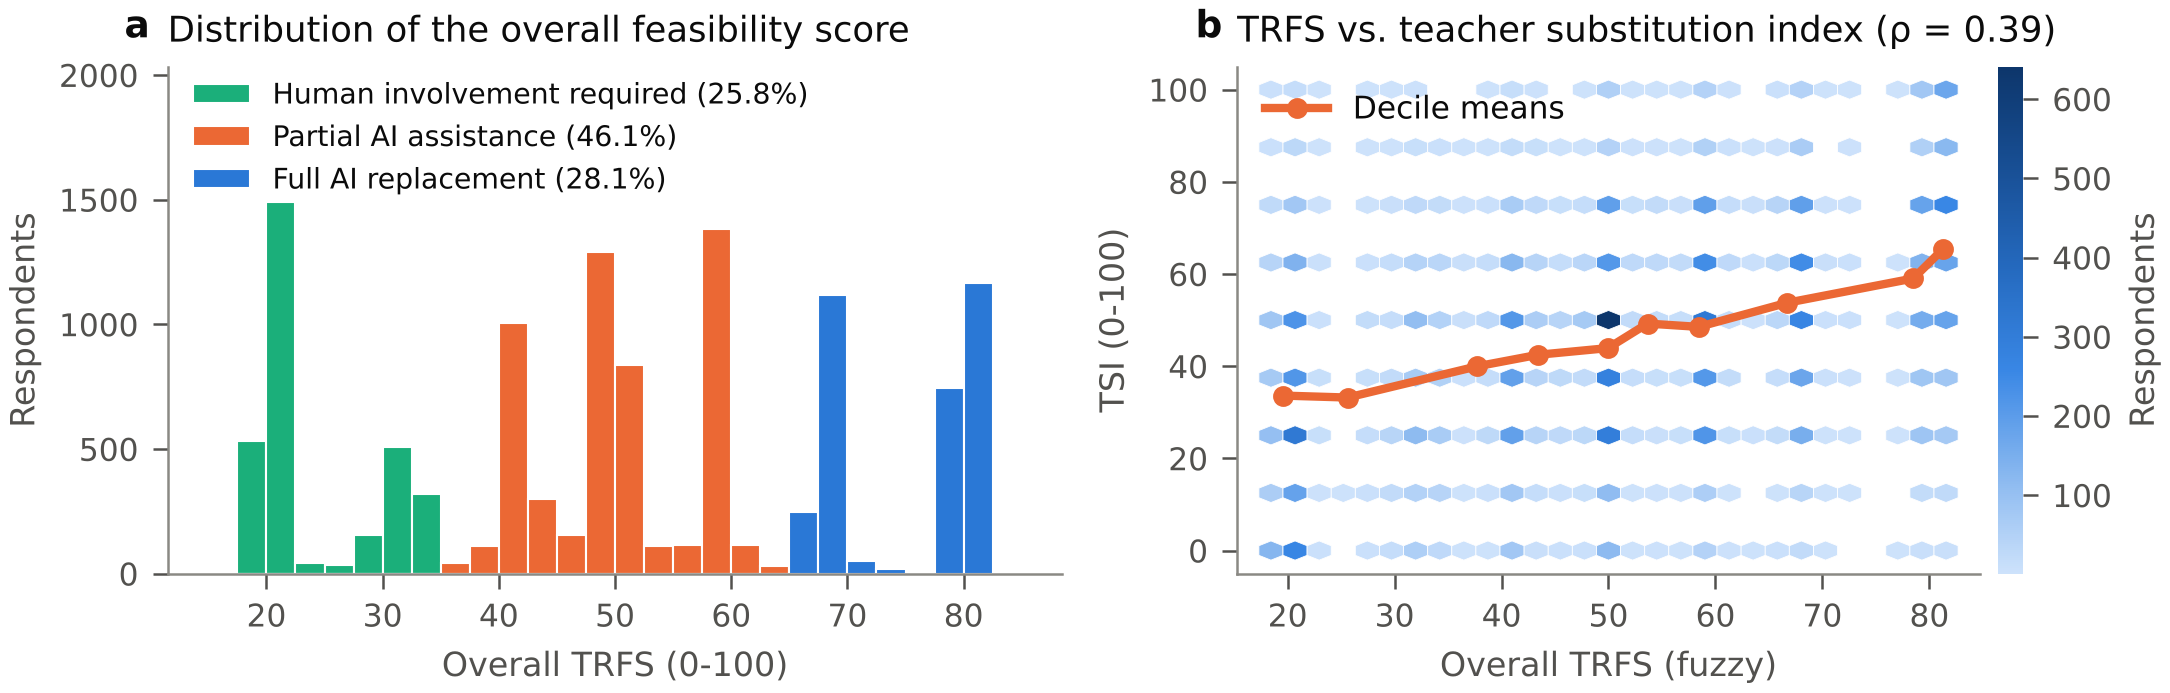

fig6_model_comparison.png


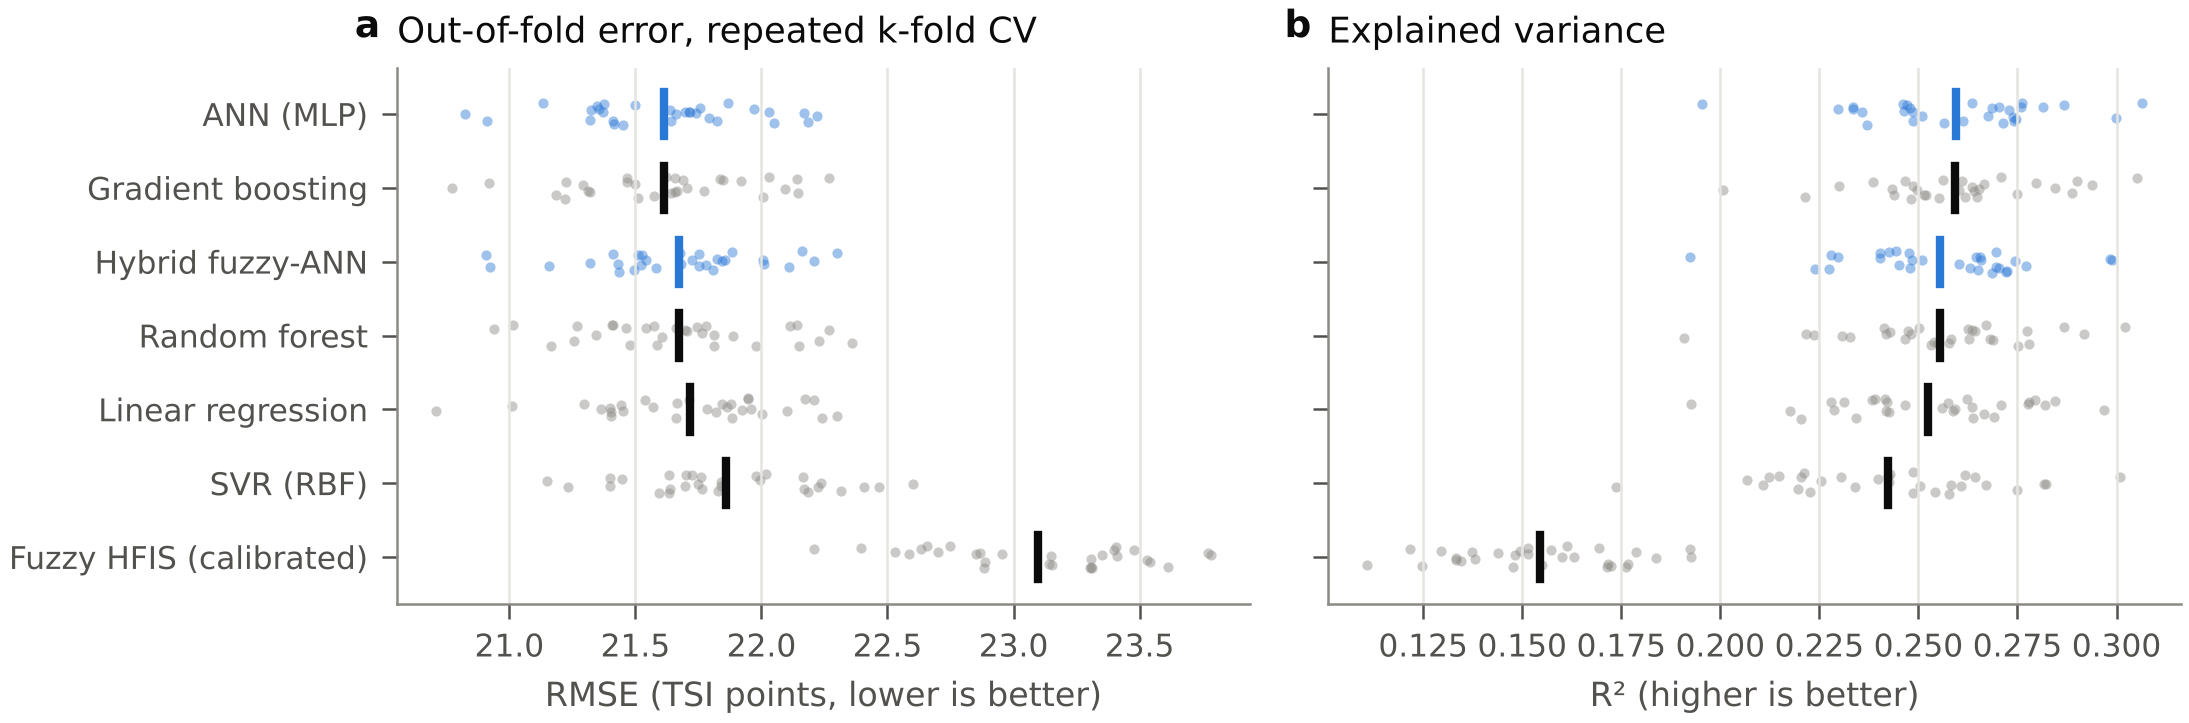

fig7_factor_importance.png


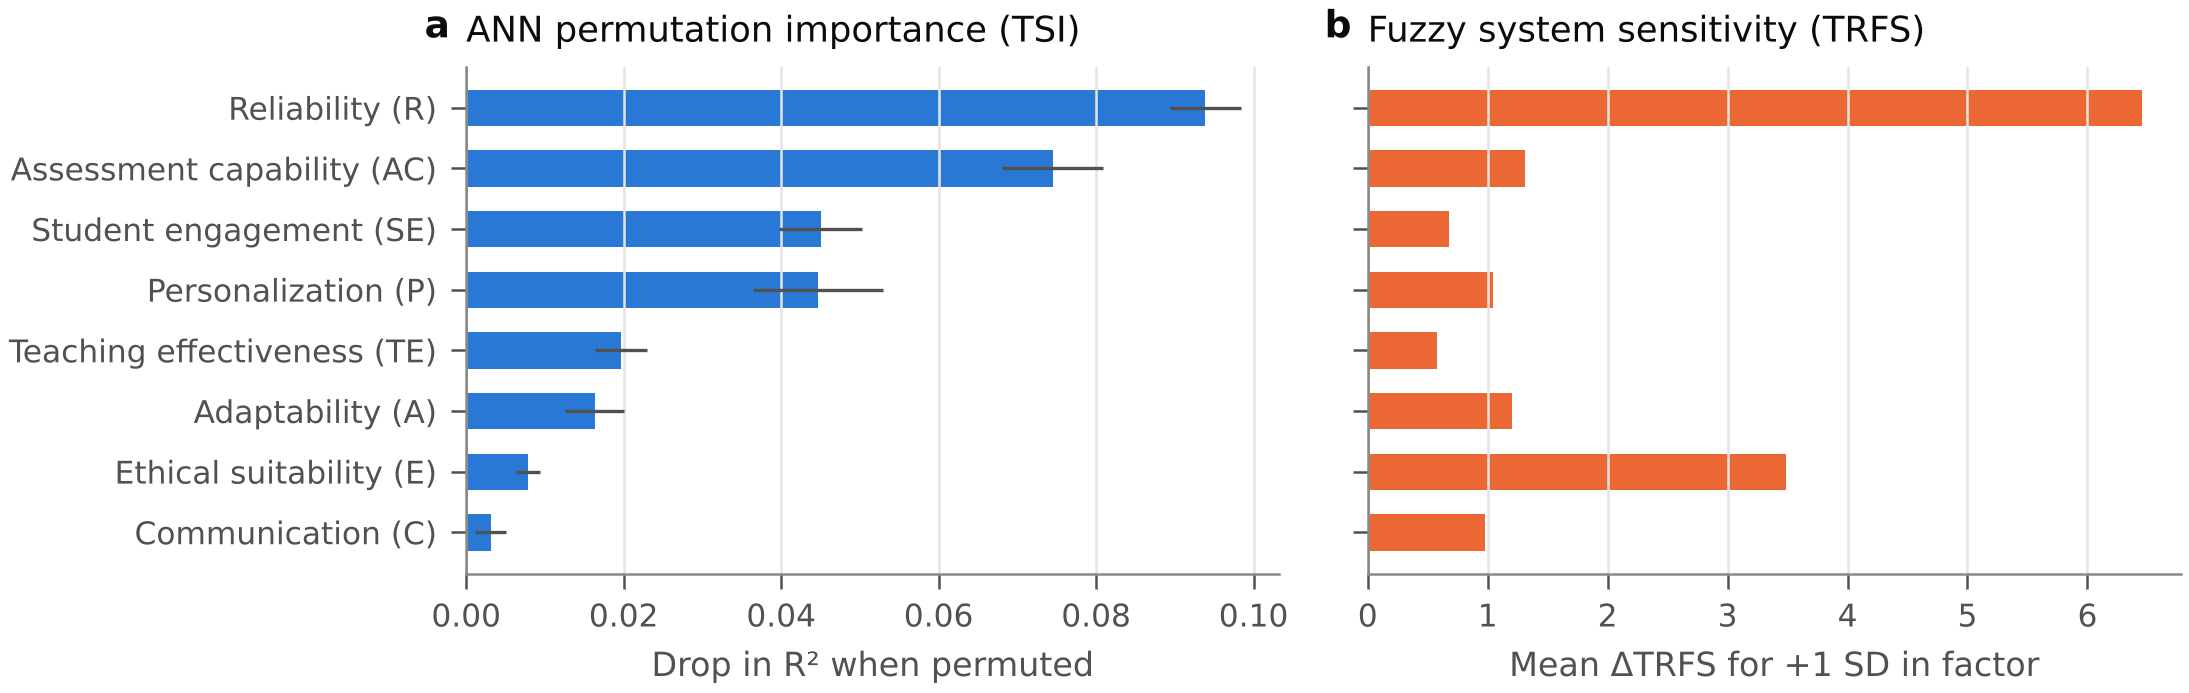

fig8_activity_feasibility.png


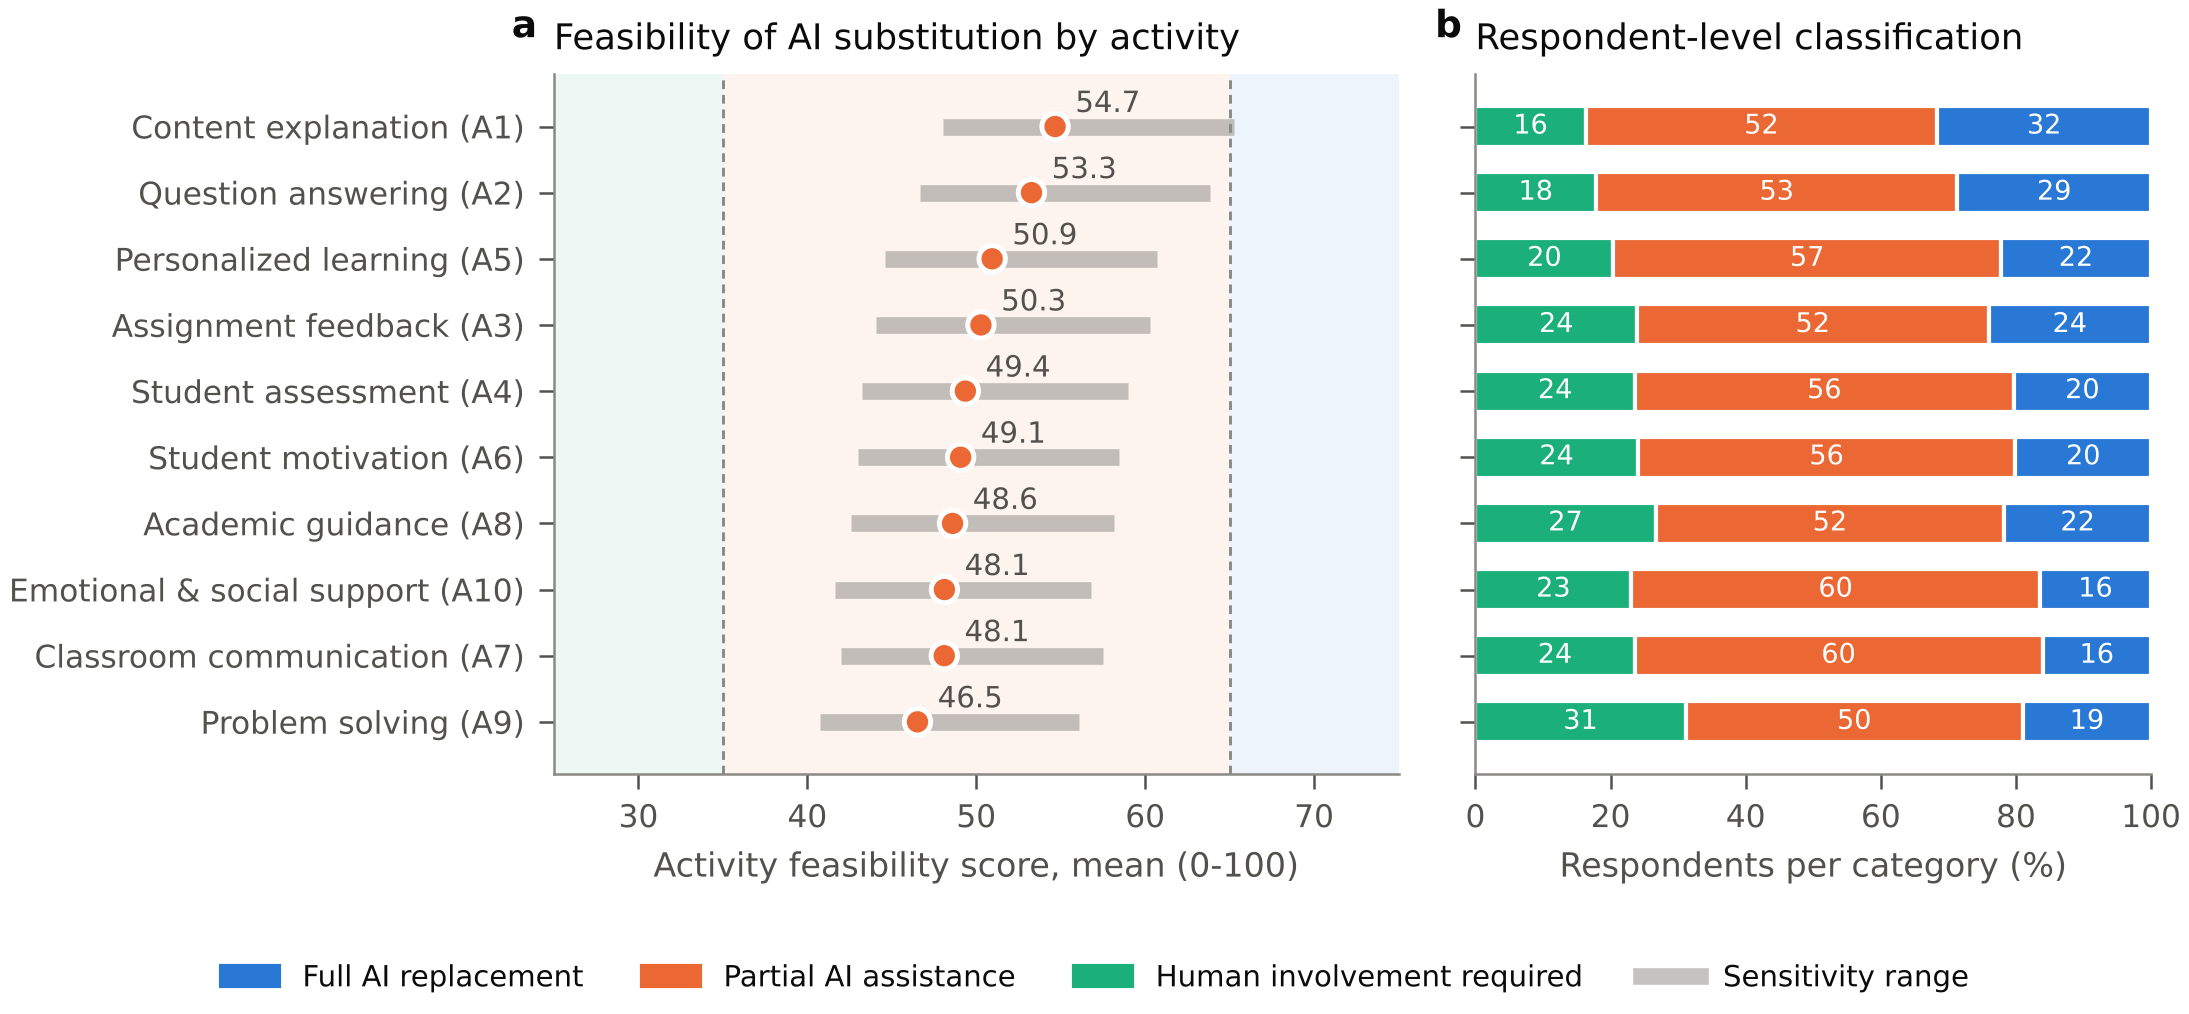

fig9_robustness.png


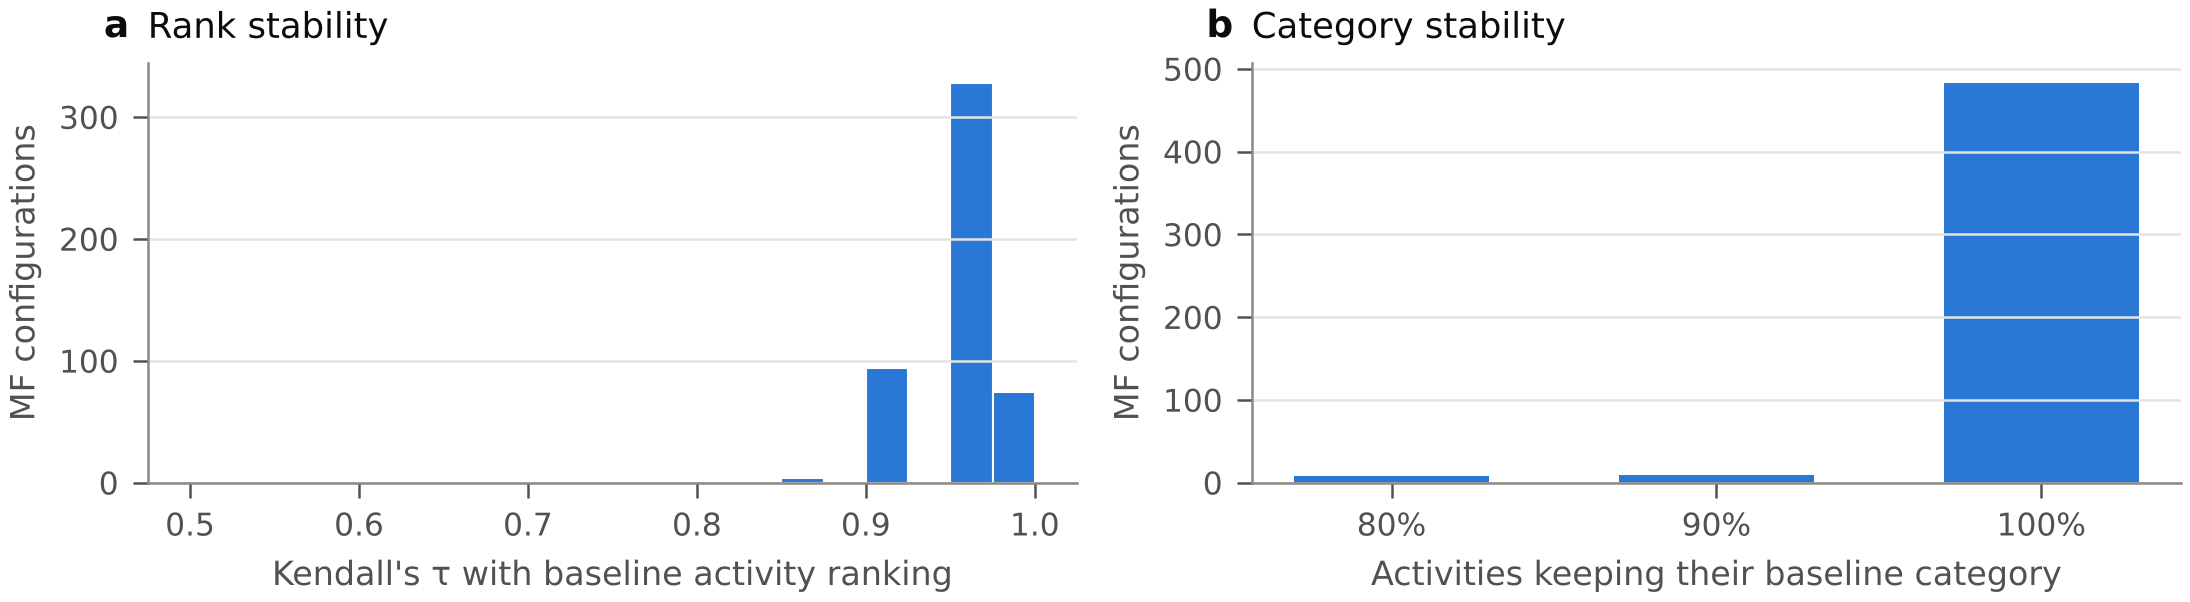

In [11]:
figures.make_all(d, ct, phi, act, cv, summ, imp, rob, band, hm)
for f in sorted(FIGURES.glob("fig*.png")):
    print(f.name); display(Image(filename=str(f), width=900))

## 9. Extended (deep) analyses
Mathematical properties of the fuzzy systems (Propositions 1-3: thresholds, closed-form centroids, rule complexity,
provably monotone weighted-average inference), exact Shapley decomposition of R², multilevel models (students in
countries), quantile regression, effect sizes + TOST equivalence, measurement invariance (Tucker's congruence) and
student typologies. Same code as `src/deep_analysis.py`.

In [12]:
import deep_analysis as da, figures_deep
d2 = pd.read_csv(PROCESSED_CSV)
prop, comp = da.math_properties(d2)
display(prop.round(3)); display(comp.round(2))

,system,rules,rule_table_monotone,grid_points,mamdani_min,mamdani_max,mamdani_worst_decrease,mamdani_share_decreasing,wa_min,wa_max,wa_worst_decrease
0,"FIS1 PC(TE,P,AC,A)",81,True,28561,18.439,81.561,-1.850,0.009,18.571,81.429,-0.0
1,"FIS2 IQ(SE,C)",9,True,1681,18.439,81.561,-1.676,0.058,18.571,81.429,0.0
2,"FIS3 TW(R,E)",9,True,1681,18.439,81.561,-1.676,0.085,18.571,81.429,-0.0
3,"FIS4 TRFS(PC,IQ,TW)",27,True,68921,18.439,81.561,-1.880,0.083,18.571,81.429,-0.0
4,"Activity FIS(Cap,R,E)",27,True,35937,18.439,81.561,-2.698,0.094,18.571,81.429,-0.0


,code,activity,mamdani,wa,wa_pct_full,wa_pct_human,rank_mamdani,rank_wa
0,A1,Content explanation,54.67,54.17,30.53,17.89,1,1
1,A2,Question answering,53.27,52.65,27.32,19.55,2,2
2,A3,Assignment feedback,50.28,49.53,23.03,25.46,4,4
3,A4,Student assessment,49.36,48.72,23.80,29.93,5,5
4,A5,Personalized learning,50.94,50.30,25.70,27.19,3,3
5,A6,Student motivation,49.08,48.38,24.03,31.91,6,6
6,A7,Classroom communication,48.11,47.15,21.22,34.40,9,8
7,A8,Academic guidance,48.60,47.78,20.80,28.40,7,7
8,A9,Problem solving,46.52,45.71,18.08,32.48,10,10
9,A10,Emotional & social support,48.12,46.94,19.79,32.07,8,9


In [13]:
sh = da.dominance(d2, B=500)
print("sum of Shapley values =", round(sh.shapley_R2.sum(), 4), "= R² of the full model")
display(sh.round(4))
fe = da.multilevel(d2)
print({k: round(v, 3) for k, v in da.OUT["multilevel"].items() if isinstance(v, float)})
display(fe.round(3))

sum of Shapley values = 0.2549 = R² of the full model


,factor,name,shapley_R2,ci_low,ci_high,share_pct
3,AC,Assessment capability,0.0643,0.0571,0.0720,25.2202
6,R,Reliability,0.0554,0.0491,0.0628,21.7184
2,P,Personalization,0.0540,0.0483,0.0598,21.2010
1,SE,Student engagement,0.0449,0.0392,0.0508,17.6074
5,A,Adaptability,0.0204,0.0170,0.0240,8.0201
0,TE,Teaching effectiveness,0.0090,0.0082,0.0100,3.5304
4,C,Communication,0.0049,0.0041,0.0062,1.9150
7,E,Ethical suitability,0.0020,0.0013,0.0033,0.7875


{'icc_TSI': np.float64(0.084), 'icc_TRFS': np.float64(0.09), 'icc_TSI_conditional': np.float64(0.051), 'R2_marginal': np.float64(0.239), 'R2_conditional': np.float64(0.278), 'LR': np.float64(342.677), 'p_LR': np.float64(0.0)}


,term,beta,se,p,ci_low,ci_high,ols_beta
0,Intercept,46.610,0.742,0.000,45.156,48.064,46.518
1,zTE,-1.944,0.263,0.000,-2.459,-1.429,-2.399
2,zSE,3.645,0.265,0.000,3.125,4.165,3.232
3,zP,2.979,0.288,0.000,2.414,3.544,3.323
4,zAC,4.648,0.282,0.000,4.095,5.201,4.754
5,zC,-0.490,0.237,0.039,-0.953,-0.026,-0.653
6,zA,1.494,0.253,0.000,0.998,1.990,1.479
7,zR,4.376,0.263,0.000,3.861,4.891,5.204
8,zE,-0.023,0.205,0.910,-0.425,0.379,-0.137


In [14]:
q, ols = da.quantile_reg(d2)
eff = da.activity_effects(d2)
inv = da.invariance(d2)
sel = da.typology(d2)
display(q.round(2)); display(eff.round(3)); display(inv.round(3)); display(sel.round(3))

,tau,beta,ci_low,ci_high
0,0.10,4.90,4.58,5.23
1,0.15,5.34,5.02,5.66
2,0.20,5.64,5.32,5.97
3,0.25,5.58,5.26,5.90
4,0.30,5.48,5.17,5.79
5,0.35,5.52,5.21,5.82
6,0.40,5.65,5.35,5.95
7,0.45,5.68,5.40,5.96
8,0.50,5.73,5.46,6.00
9,0.55,5.70,5.43,5.96


,code,activity,mean,cohen_d_vs_50,d_ci_low,d_ci_high,p_tost_equiv_50,equivalent_to_50,p_below_65
0,A1,Content explanation,54.668,0.253,0.235,0.271,1.000,False,0.0
1,A2,Question answering,53.272,0.179,0.161,0.197,1.000,False,0.0
4,A5,Personalized learning,50.942,0.049,0.031,0.067,0.000,True,0.0
2,A3,Assignment feedback,50.277,0.015,-0.003,0.033,0.000,True,0.0
3,A4,Student assessment,49.357,-0.033,-0.051,-0.015,0.000,True,0.0
5,A6,Student motivation,49.075,-0.047,-0.065,-0.029,0.000,True,0.0
7,A8,Academic guidance,48.598,-0.073,-0.091,-0.055,0.000,True,0.0
9,A10,Emotional & social support,48.116,-0.105,-0.123,-0.087,0.241,False,0.0
6,A7,Classroom communication,48.107,-0.100,-0.118,-0.082,0.269,False,0.0
8,A9,Problem solving,46.522,-0.179,-0.197,-0.161,1.000,False,0.0


,grouping,group,n,CFI,RMSEA,SRMR,min_congruence,mean_congruence,max_abs_loading_diff
0,Gender,Female,6476,0.939,0.053,0.048,1.000,1.000,0.026
1,Gender,Male,5266,0.936,0.053,0.046,1.000,1.000,0.037
2,Level,Postgraduate,1971,0.938,0.053,0.046,0.999,0.999,0.082
3,Level,Undergraduate,9856,0.939,0.052,0.046,1.000,1.000,0.014
4,Field,Applied Sciences,4274,0.939,0.052,0.045,1.000,1.000,0.033
5,Field,Arts & Humanities,1423,0.927,0.058,0.054,0.999,1.000,0.077
6,Field,Natural & Life Sciences,1291,0.939,0.055,0.047,0.999,1.000,0.048
7,Field,Social Sciences,4824,0.938,0.052,0.047,1.000,1.000,0.040
8,Language,Arabic,448,0.930,0.062,0.049,0.987,0.995,0.153
9,Language,English,7422,0.939,0.052,0.046,1.000,1.000,0.028


,k,silhouette,calinski_harabasz,bootstrap_ARI
0,2,0.262,5794.935,0.986
1,3,0.197,4416.756,0.957
2,4,0.149,3535.374,0.935
3,5,0.142,2988.166,0.921
4,6,0.128,2617.623,0.924


fig11_activity_raincloud.png


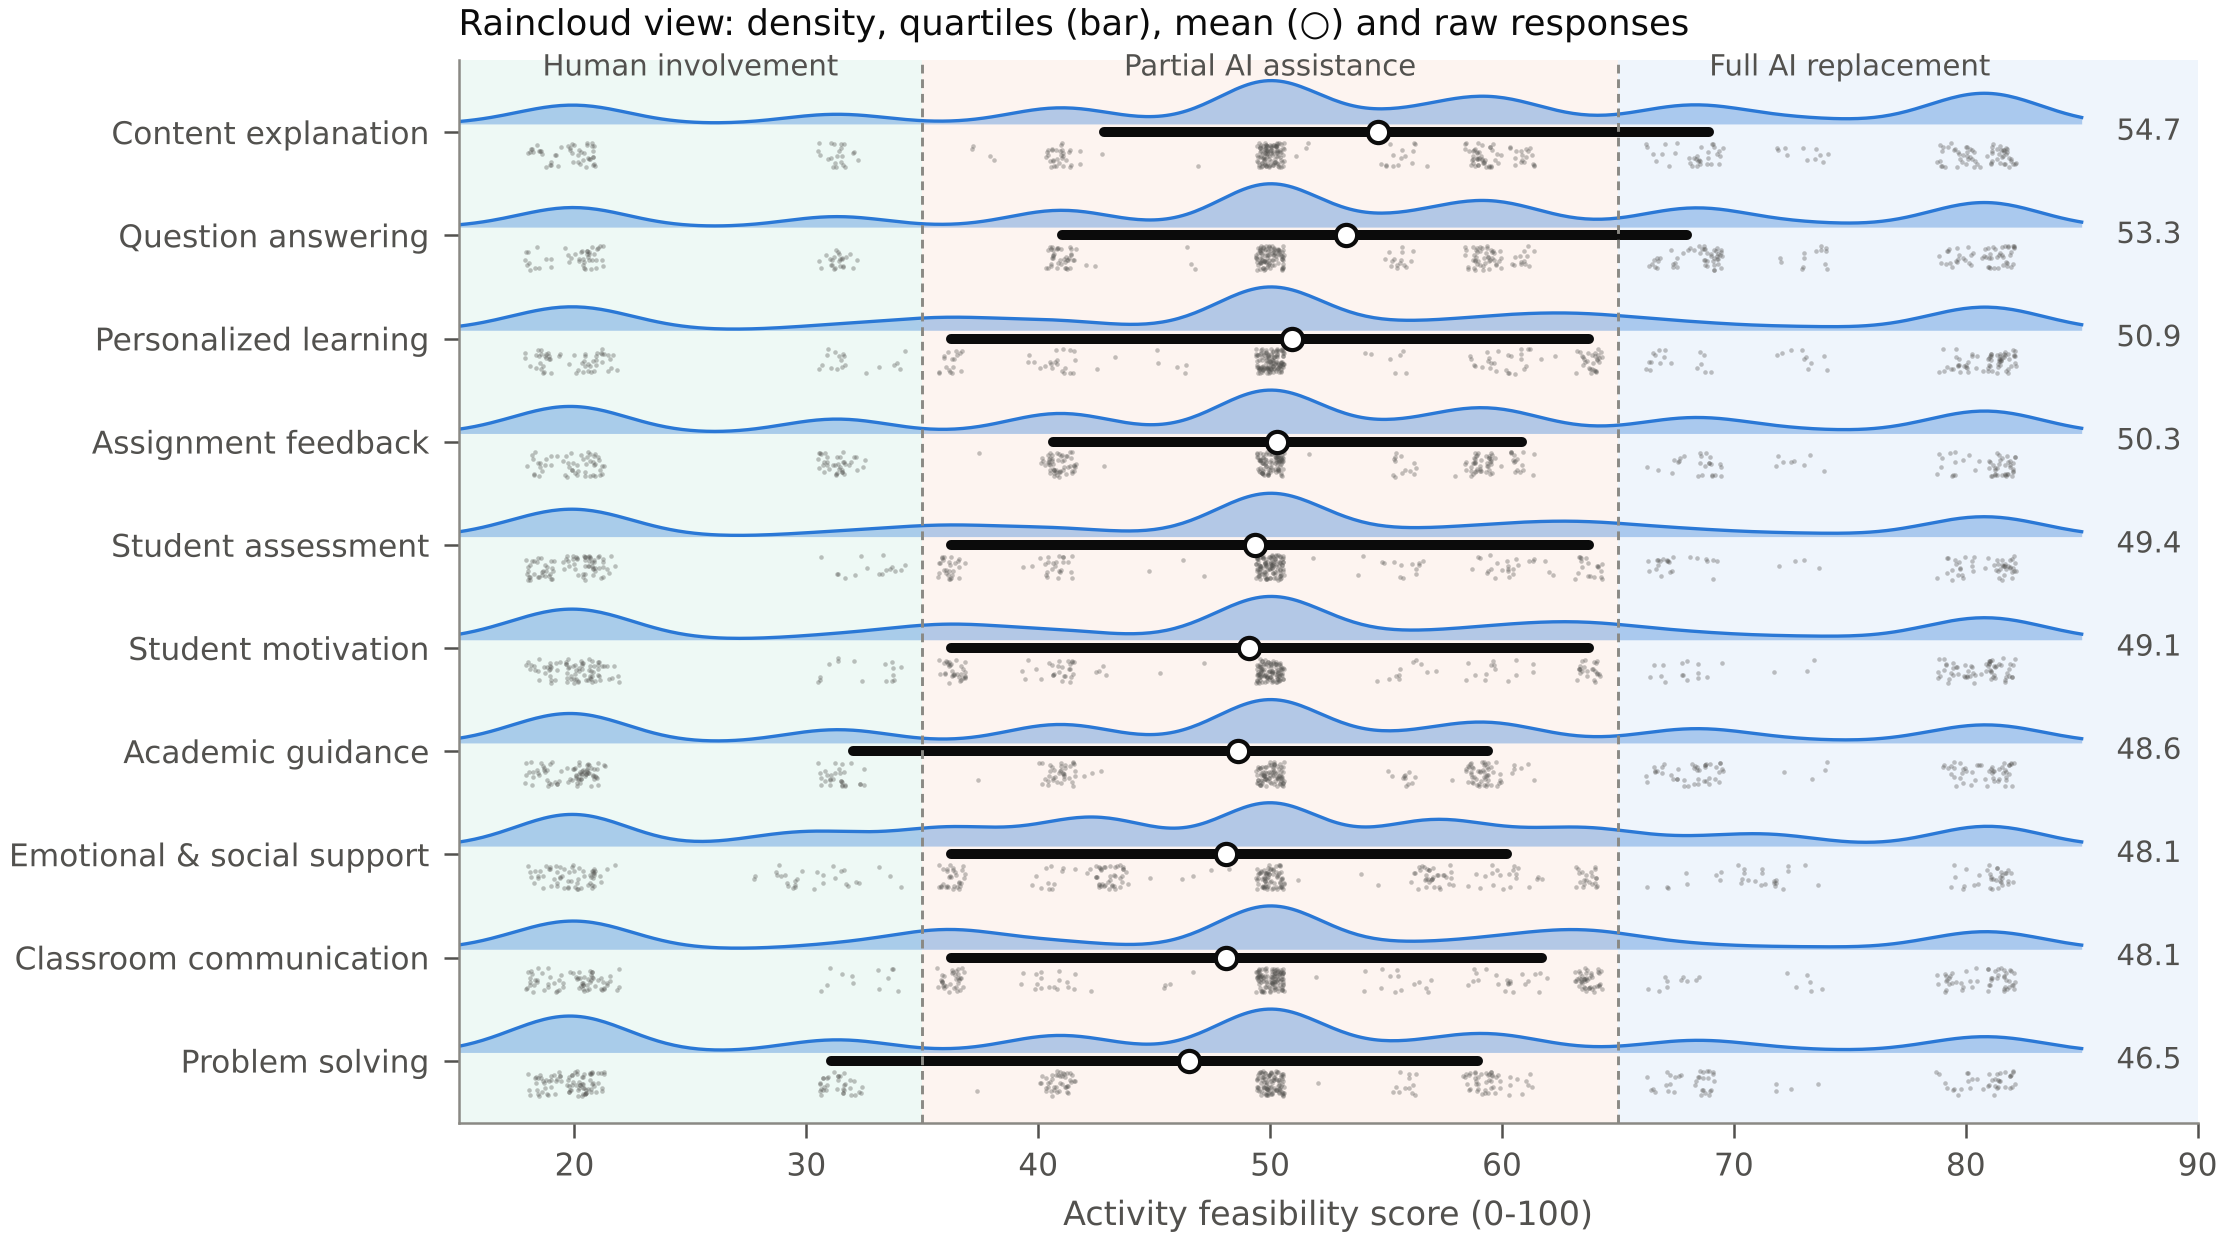

fig12_shapley_r2.png


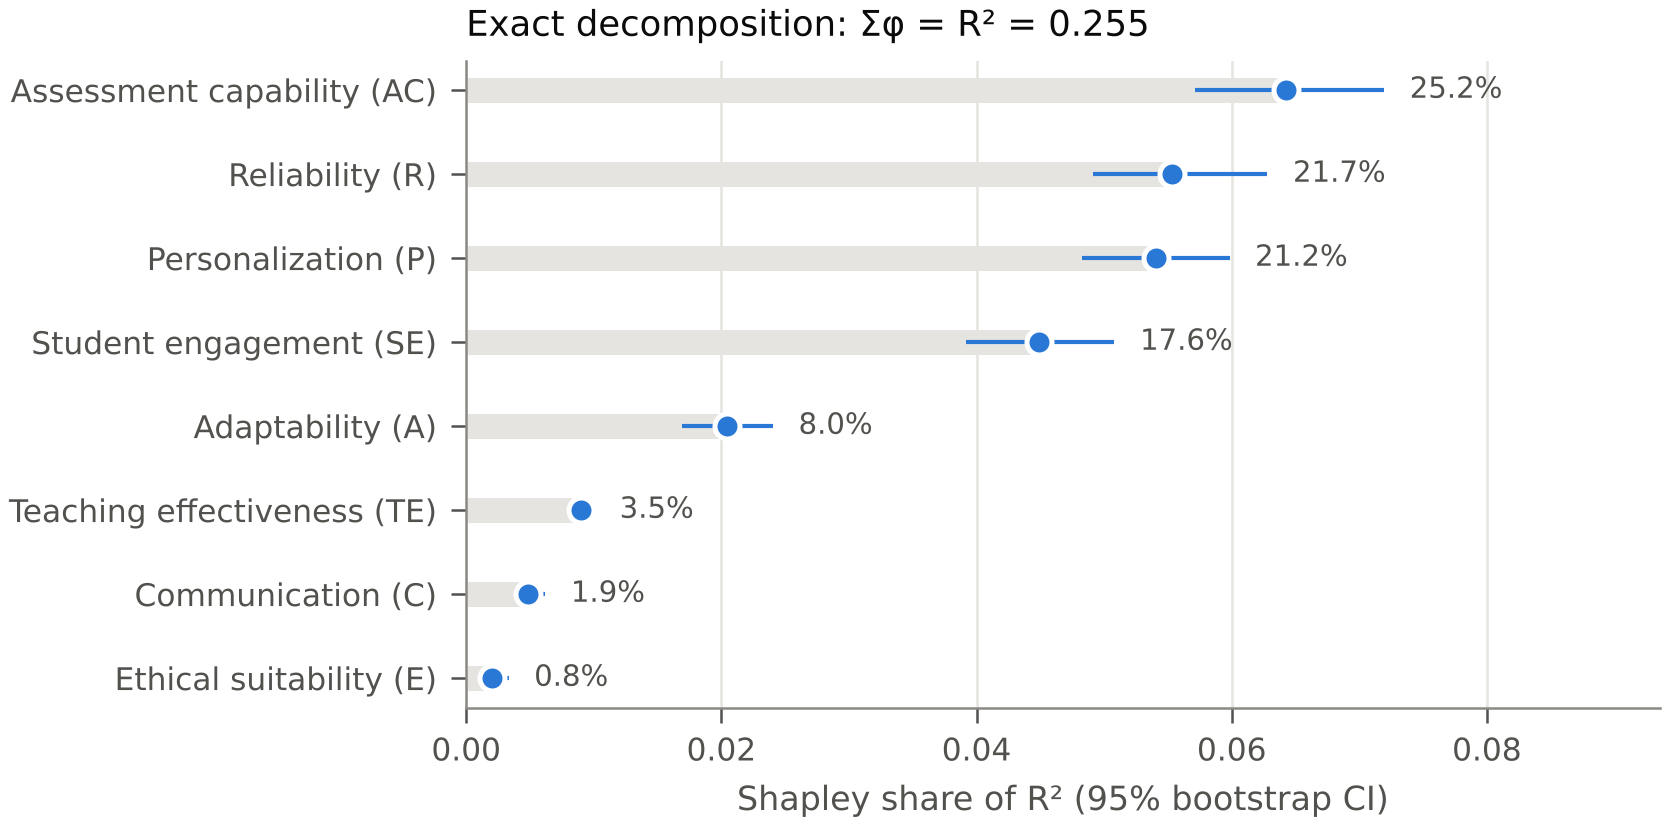

fig13_multilevel.png


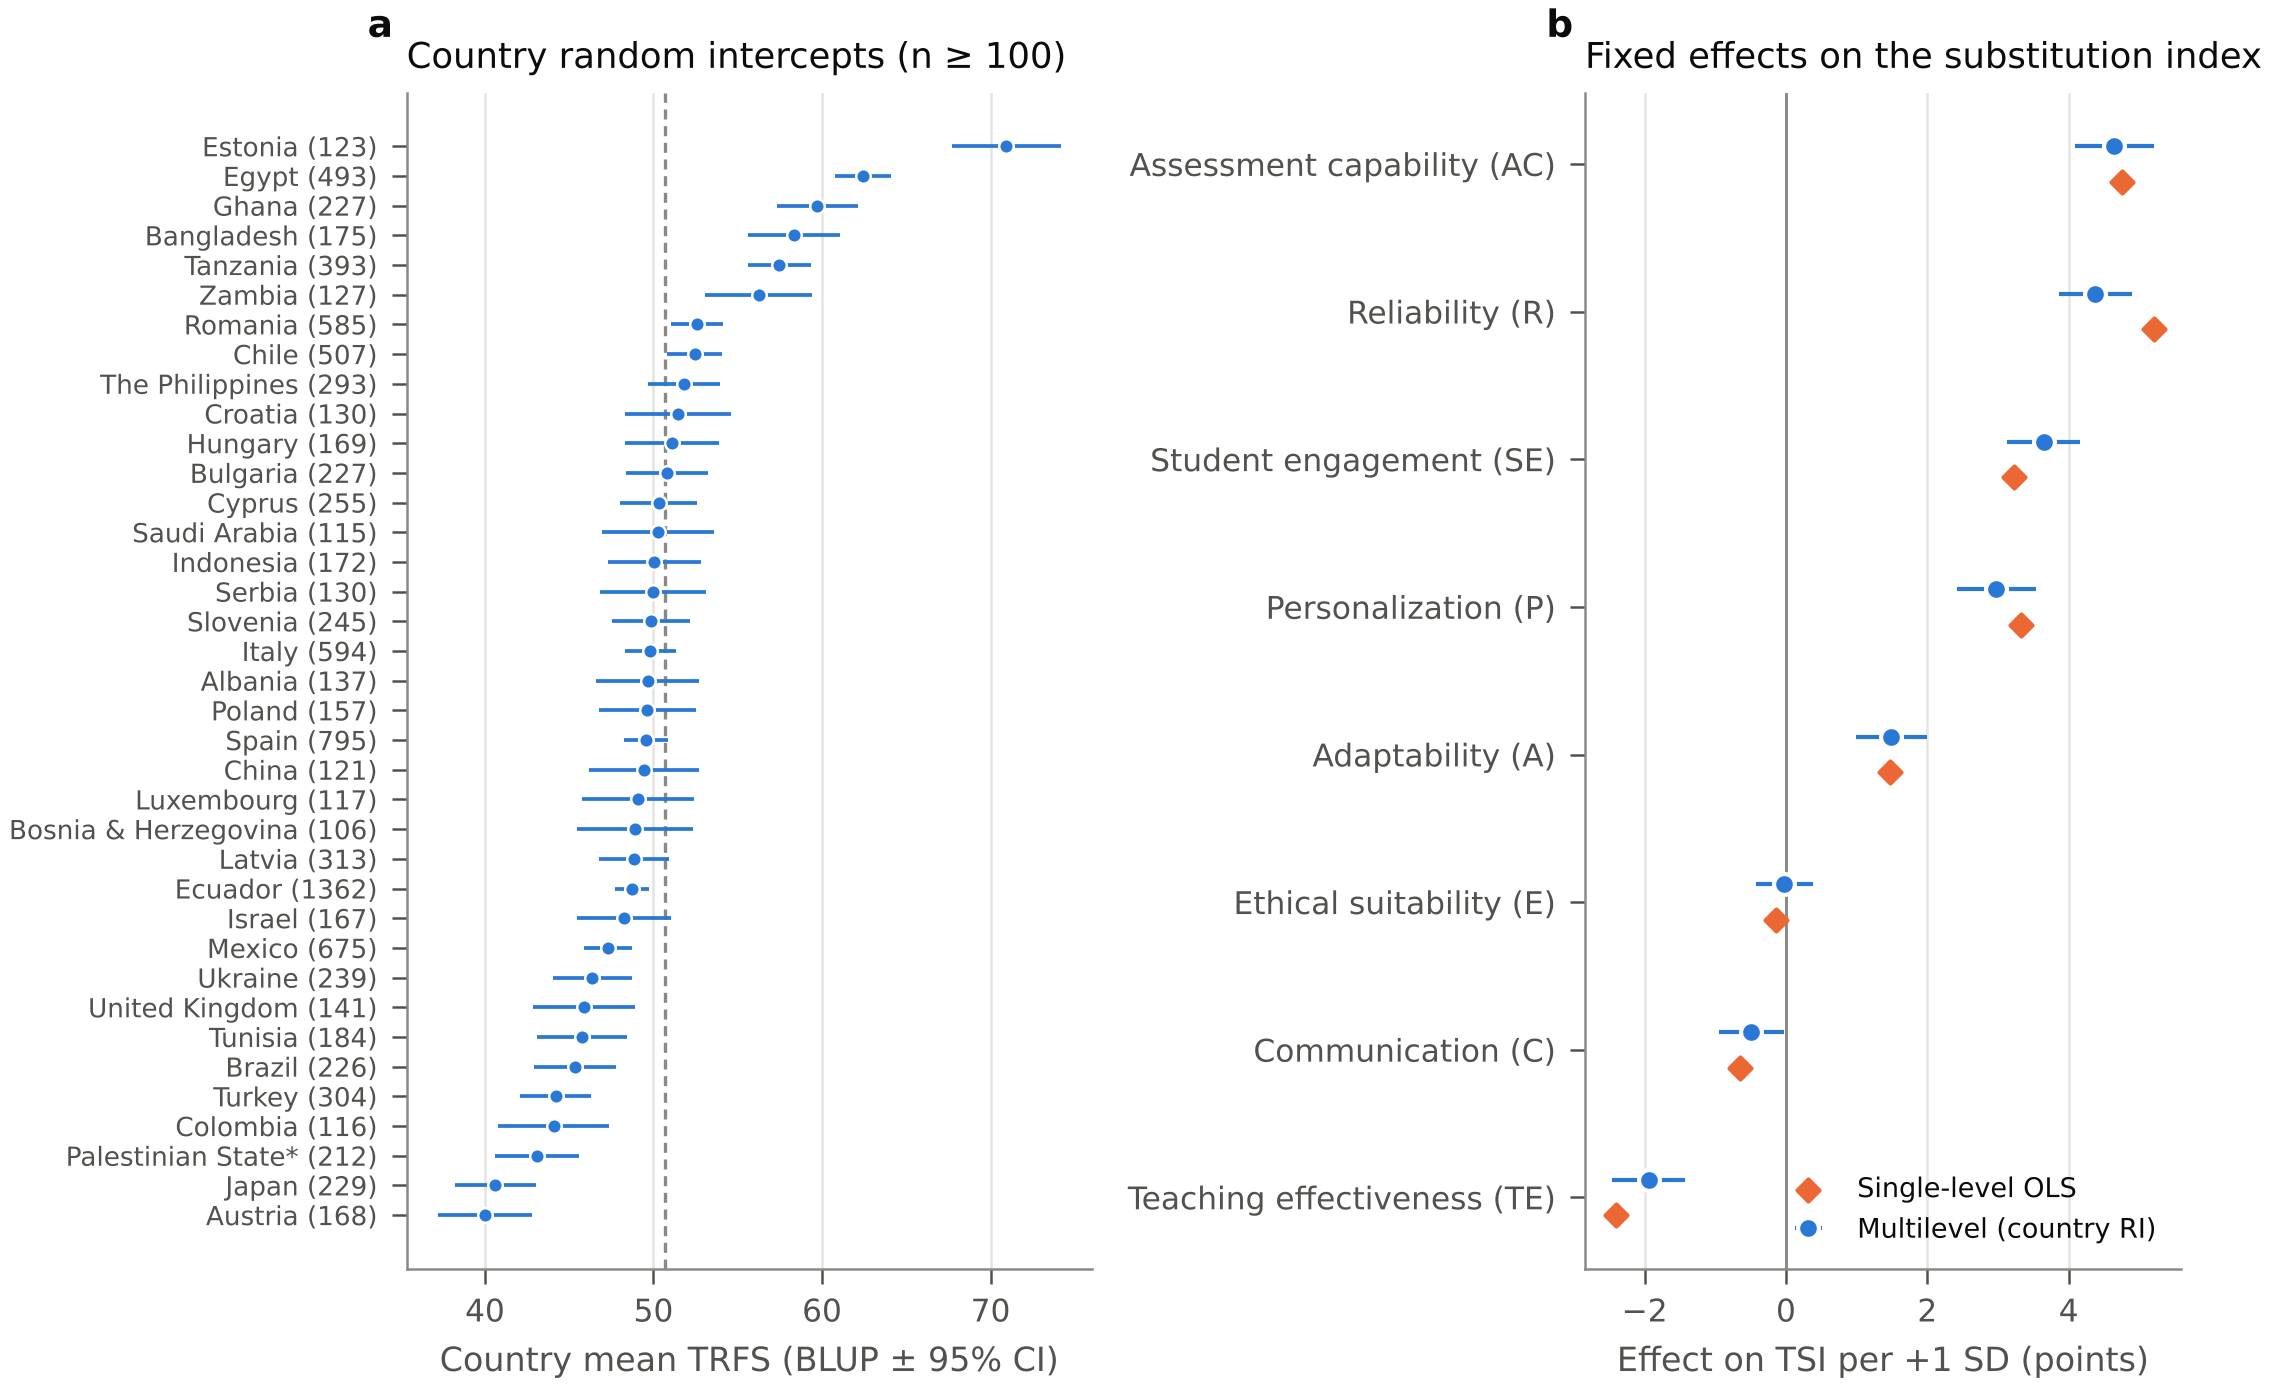

fig14_quantile_regression.png


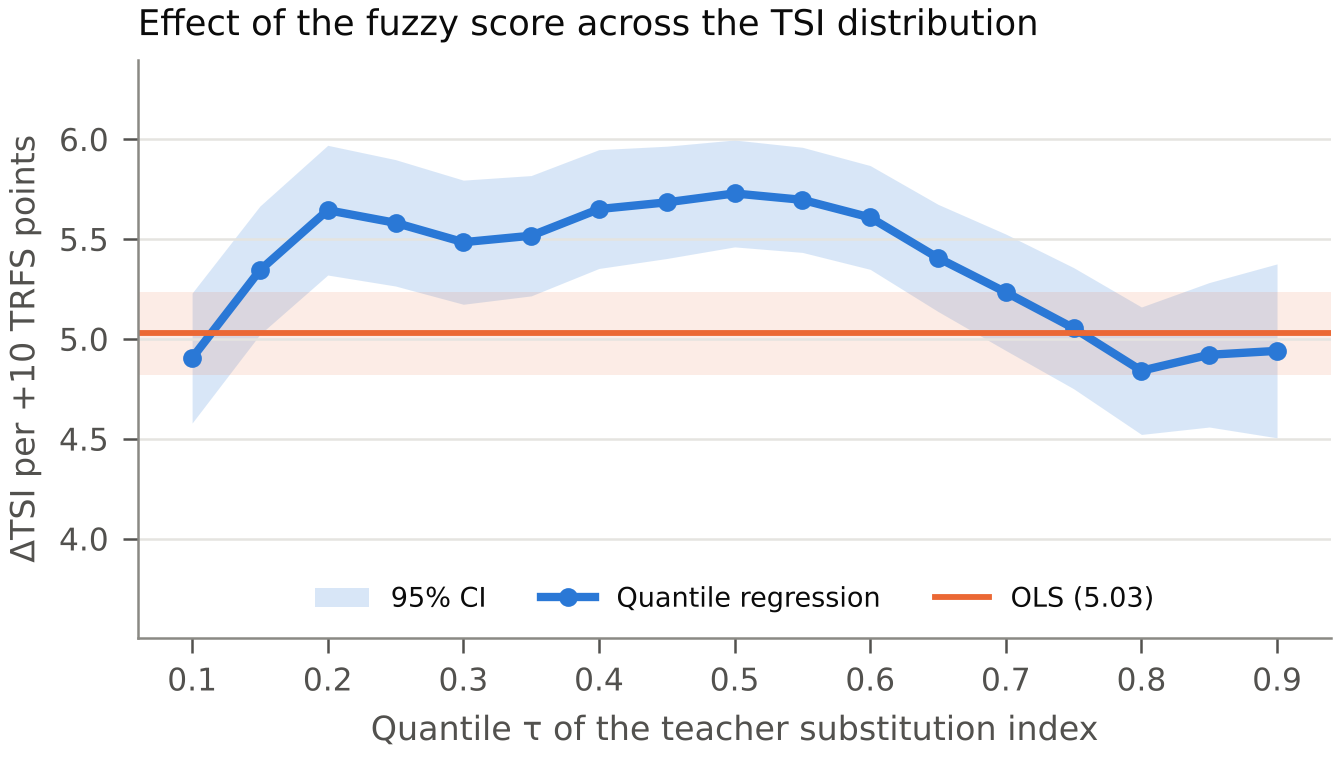

fig15_typology.png


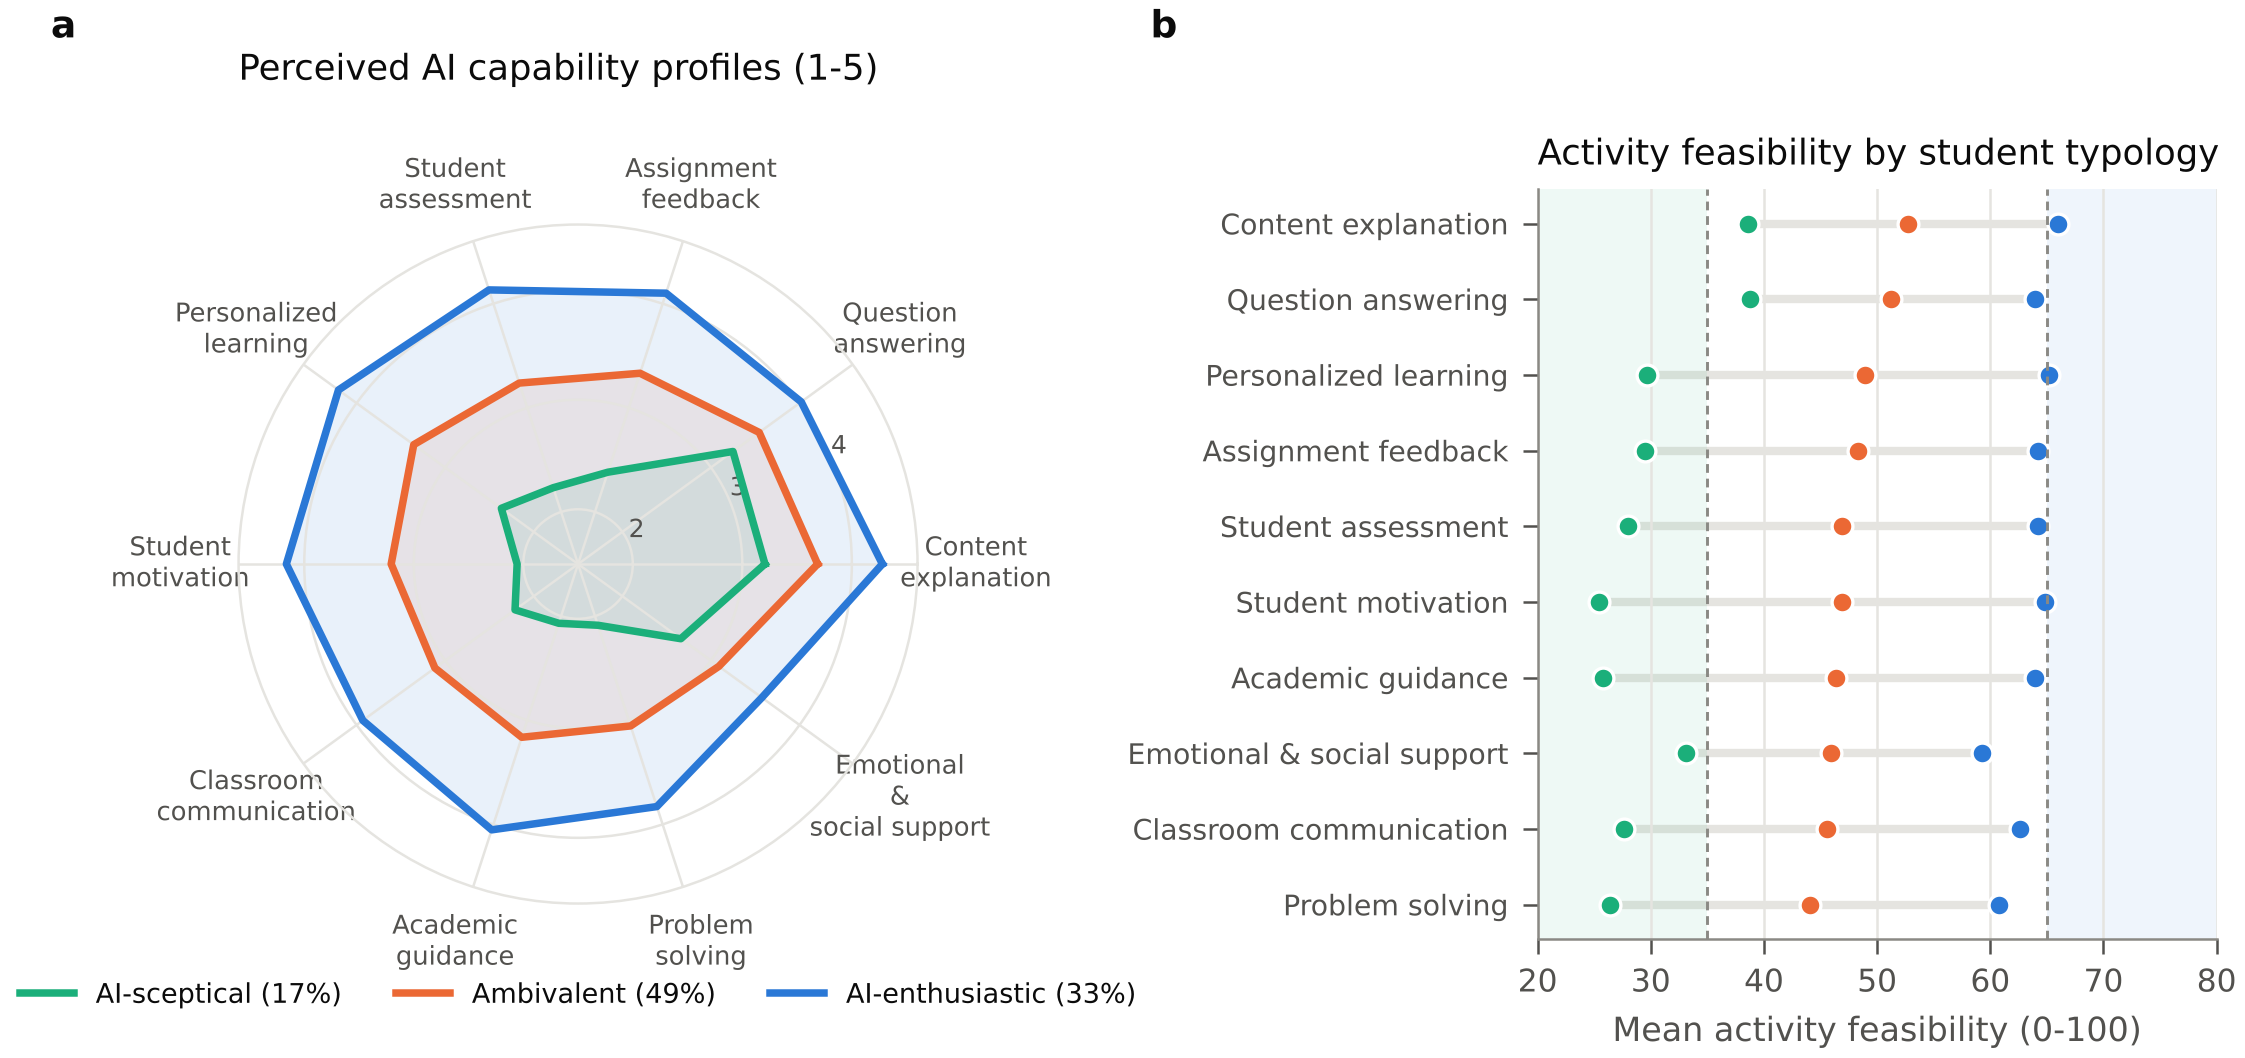

fig16_surfaces_3d.png


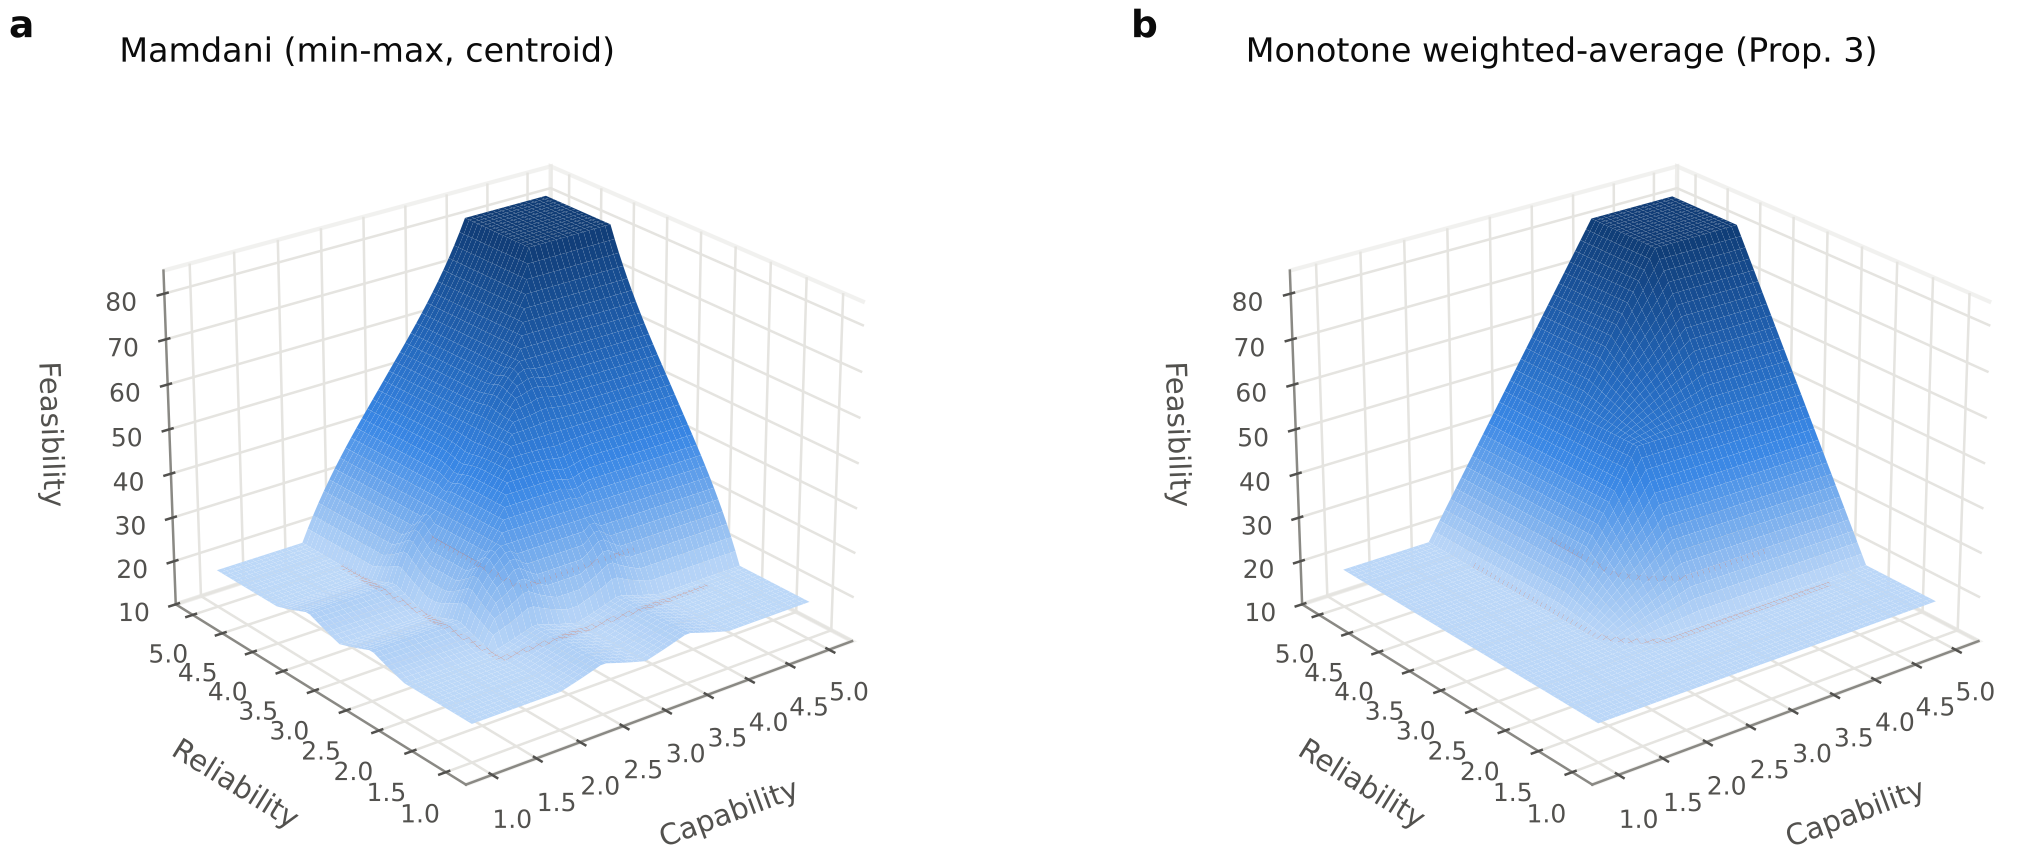

fig17_effects_and_variants.png


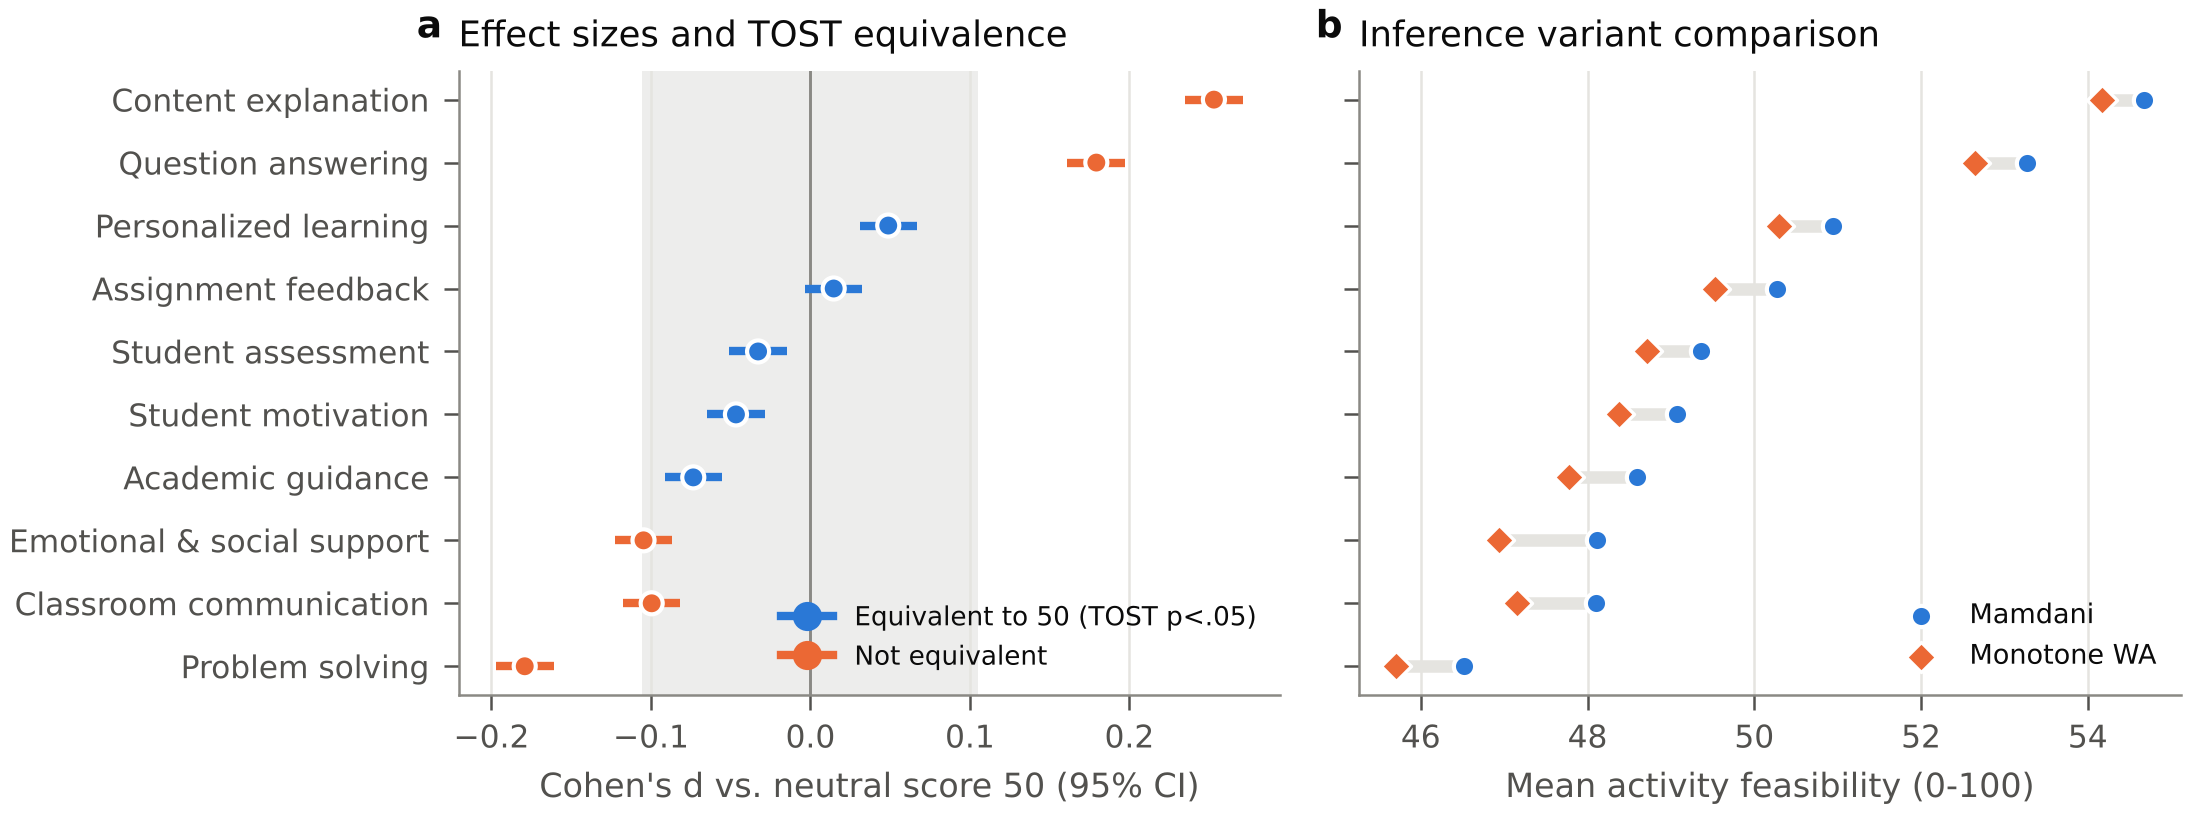

In [15]:
figures_deep.make_all(d2, prop, comp, sh, q, eff, da.OUT)
for f in sorted(FIGURES.glob("fig1[1-7]*.png")):
    print(f.name); display(Image(filename=str(f), width=900))